# Friendship communities and held-out artist recommendation

**DSA5101 standalone analysis — frozen protocol `lastfm-v1`**

This notebook reconstructs the complete analysis from the original HetRec 2011 Last.fm 2K ZIP. It contains all loading, splitting, modelling, selection, inference, and robustness logic needed for execution. It does not import local project modules or read cached results.

## 1. Research question and dataset

**Question.** Do friendship-graph communities improve held-out artist recommendation beyond listening-history-based matrix factorization, particularly for users with sparse *observed training* histories?

The data are aggregate user–artist listening counts and a reciprocal friendship graph. They contain no listening-event timestamps, so the deterministic within-user split is not a forecast. H1 is a descriptive association, not a causal friendship effect. H2 is the sole primary confirmatory comparison. H3 retains the frozen sparse definition even if that makes it non-estimable.

**Dataset and citation.** HetRec 2011 Last.fm 2K, version 1.0 (May 2011). When using the dataset, cite Last.fm and: Cantador, I., Brusilovsky, P., & Kuflik, T. (2011), *2nd Workshop on Information Heterogeneity and Fusion in Recommender Systems (HetRec 2011)*, Proceedings of RecSys 2011, ACM. The bundled notice permits non-commercial use; raw data are not redistributed here.

**Obtaining the data.** Download the original archive from the verified GroupLens source: https://files.grouplens.org/datasets/hetrec2011/hetrec2011-lastfm-2k.zip. Place `hetrec2011-lastfm-2k.zip` beside this notebook, keep it at `data/raw/hetrec2011-lastfm-2k.zip`, or set environment variable `LASTFM_ARCHIVE` to its path. Execution verifies SHA-256 `6738f48195667ff03caaab4d32ca9a3133d8cc026b7c3cdaf6ce1010e913c59c` and the ZIP CRC before parsing.

In [1]:
# Set deterministic numerical threading before importing NumPy/implicit.
import os
for _name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[_name] = "1"

CHECKPOINT_ATOL = 1e-6  # Cross-platform floating-point tolerance; counts/configs are exact.

## 2. Data quality and preparation

The next cells inline the approved P2–P5 implementation. Required source members are decoded without replacement, schemas and integer ranges are checked, reciprocal friendships are canonicalized, and all 92,834 observed pairs are conserved. The split seed is 5101; users with at least seven pairs receive a deterministic 70/15/15 largest-remainder split, while lower-history users remain fit-only. Sparse labels are frozen from split-training counts before validation.

In [2]:
"""Validated, deterministic loading of the frozen HetRec Last.fm archive."""

from __future__ import annotations

from dataclasses import dataclass
from hashlib import sha256
from pathlib import Path
import re
from typing import Iterable
from zipfile import BadZipFile, ZipFile

import pandas as pd


ARCHIVE_SHA256 = "6738f48195667ff03caaab4d32ca9a3133d8cc026b7c3cdaf6ce1010e913c59c"
REQUIRED_MEMBERS = frozenset({"user_artists.dat", "user_friends.dat", "artists.dat"})
FROZEN_MEMBERS = frozenset(
    {
        "artists.dat",
        "readme.txt",
        "tags.dat",
        "user_artists.dat",
        "user_friends.dat",
        "user_taggedartists.dat",
        "user_taggedartists-timestamps.dat",
    }
)

_INT_RE = re.compile(r"^[+-]?\d+$")
_INT64_MIN = -(2**63)
_INT64_MAX = 2**63 - 1


class ArchiveIntegrityError(ValueError):
    """Raised when the archive identity or ZIP integrity is invalid."""


class DataValidationError(ValueError):
    """Raised when a required source-table contract is violated."""


@dataclass(frozen=True)
class FriendshipTables:
    """Validated friendship representations."""

    directed: pd.DataFrame
    undirected: pd.DataFrame


@dataclass(frozen=True)
class HetRecData:
    """All P2.1 tables and deterministic raw-ID mappings."""

    interactions: pd.DataFrame
    friendships: FriendshipTables
    artists: pd.DataFrame
    user_index: pd.DataFrame
    artist_index: pd.DataFrame


def _sha256(path: Path) -> str:
    digest = sha256()
    try:
        with path.open("rb") as source:
            for chunk in iter(lambda: source.read(1024 * 1024), b""):
                digest.update(chunk)
    except OSError as exc:
        raise ArchiveIntegrityError(f"Cannot read archive {path}: {exc}") from exc
    return digest.hexdigest()


def _open_checked_archive(archive_path: Path, *, verify_checksum: bool) -> ZipFile:
    archive_path = Path(archive_path)
    if not archive_path.is_file():
        raise ArchiveIntegrityError(f"Archive does not exist: {archive_path}")
    if verify_checksum:
        actual = _sha256(archive_path)
        if actual != ARCHIVE_SHA256:
            raise ArchiveIntegrityError(
                f"Archive SHA-256 mismatch: expected {ARCHIVE_SHA256}, got {actual}"
            )
    try:
        zf = ZipFile(archive_path)
    except (BadZipFile, OSError) as exc:
        raise ArchiveIntegrityError(f"Invalid ZIP archive {archive_path}: {exc}") from exc
    names = [info.filename for info in zf.infolist()]
    if len(names) != len(set(names)):
        zf.close()
        raise ArchiveIntegrityError("ZIP contains duplicate member names")
    actual_names = frozenset(names)
    if not REQUIRED_MEMBERS <= actual_names:
        missing = sorted(REQUIRED_MEMBERS - actual_names)
        zf.close()
        raise ArchiveIntegrityError(f"ZIP is missing required members: {missing}")
    if actual_names not in (REQUIRED_MEMBERS, FROZEN_MEMBERS):
        unexpected = sorted(actual_names - FROZEN_MEMBERS)
        missing = sorted(FROZEN_MEMBERS - actual_names)
        zf.close()
        raise ArchiveIntegrityError(
            f"Unexpected ZIP member set; missing={missing}, unexpected={unexpected}"
        )
    try:
        bad = zf.testzip()
    except (BadZipFile, OSError, RuntimeError) as exc:
        zf.close()
        raise ArchiveIntegrityError(f"ZIP CRC validation failed: {exc}") from exc
    if bad is not None:
        zf.close()
        raise ArchiveIntegrityError(f"ZIP CRC validation failed for member {bad!r}")
    return zf


def _read_rows(
    zf: ZipFile,
    member: str,
    expected_header: tuple[str, ...],
    *,
    nullable_fields: frozenset[int] = frozenset(),
) -> list[tuple[int, list[str]]]:
    try:
        raw = zf.read(member)
    except (KeyError, BadZipFile) as exc:
        raise ArchiveIntegrityError(f"Cannot read ZIP member {member!r}: {exc}") from exc
    try:
        text = raw.decode("utf-8")
    except UnicodeDecodeError as exc:
        raise DataValidationError(f"{member}: invalid UTF-8 at byte {exc.start}") from exc
    if not text.endswith("\n"):
        raise DataValidationError(f"{member}: missing final newline")
    lines = text.splitlines()
    if not lines:
        raise DataValidationError(f"{member}: empty file")
    header = lines[0].split("\t")
    if tuple(header) != expected_header:
        raise DataValidationError(
            f"{member}: invalid header {header!r}; expected {list(expected_header)!r}"
        )
    rows: list[tuple[int, list[str]]] = []
    for line_number, line in enumerate(lines[1:], 2):
        fields = line.split("\t")
        if len(fields) != len(expected_header):
            raise DataValidationError(
                f"{member}: row {line_number} has {len(fields)} fields; "
                f"expected {len(expected_header)}"
            )
        if any(field == "" and index not in nullable_fields for index, field in enumerate(fields)):
            raise DataValidationError(f"{member}: row {line_number} contains a null field")
        rows.append((line_number, fields))
    return rows


def _integer(value: str, member: str, line: int, field: str) -> int:
    if not _INT_RE.fullmatch(value):
        raise DataValidationError(f"{member}: row {line} field {field!r} is not an integer: {value!r}")
    parsed = int(value)
    if not _INT64_MIN <= parsed <= _INT64_MAX:
        raise DataValidationError(
            f"{member}: row {line} field {field!r} is outside signed int64 range: {value!r}"
        )
    return parsed


def _frame(rows: Iterable[tuple[int, list[str]]], member: str, columns: tuple[str, ...]) -> pd.DataFrame:
    return pd.DataFrame([fields for _, fields in rows], columns=columns)


def _validate_positive_ids(frame: pd.DataFrame, member: str, fields: Iterable[str]) -> None:
    for field in fields:
        if (frame[field] <= 0).any():
            bad = int(frame.loc[frame[field] <= 0, field].iloc[0])
            raise DataValidationError(f"{member}: {field} must be positive; found {bad}")


def load_artists(archive_path: Path, *, verify_checksum: bool = True) -> pd.DataFrame:
    """Load and validate ``artists.dat`` with canonical snake_case columns."""
    zf = _open_checked_archive(Path(archive_path), verify_checksum=verify_checksum)
    try:
        rows = _read_rows(
            zf, "artists.dat", ("id", "name", "url", "pictureURL"), nullable_fields=frozenset({3})
        )
    finally:
        zf.close()
    parsed = []
    for line, fields in rows:
        artist_id = _integer(fields[0], "artists.dat", line, "id")
        if not fields[1] or not fields[2]:
            raise DataValidationError(f"artists.dat: row {line} has an empty name or url")
        parsed.append((artist_id, fields[1], fields[2], fields[3] or pd.NA))
    frame = pd.DataFrame(parsed, columns=["artist_id", "name", "url", "picture_url"])
    frame = frame.astype({"artist_id": "int64", "name": "string", "url": "string", "picture_url": "string"})
    _validate_positive_ids(frame, "artists.dat", ("artist_id",))
    if frame["artist_id"].duplicated().any():
        raise DataValidationError("artists.dat: duplicate artist_id values")
    return frame.sort_values("artist_id", kind="mergesort", ignore_index=True)


def load_user_artists(
    archive_path: Path, *, artist_ids: Iterable[int] | None = None, verify_checksum: bool = True
) -> pd.DataFrame:
    """Load validated listening interactions, sorted by ``user_id, artist_id``."""
    zf = _open_checked_archive(Path(archive_path), verify_checksum=verify_checksum)
    try:
        rows = _read_rows(zf, "user_artists.dat", ("userID", "artistID", "weight"))
    finally:
        zf.close()
    parsed = [tuple(_integer(v, "user_artists.dat", line, field) for v, field in zip(fields, ("userID", "artistID", "weight"))) for line, fields in rows]
    frame = pd.DataFrame(parsed, columns=["user_id", "artist_id", "weight"], dtype="int64")
    _validate_positive_ids(frame, "user_artists.dat", ("user_id", "artist_id", "weight"))
    if frame.duplicated(["user_id", "artist_id"]).any():
        raise DataValidationError("user_artists.dat: duplicate user_id/artist_id pair")
    if artist_ids is not None:
        known = set(int(value) for value in artist_ids)
        missing = sorted(set(frame["artist_id"]) - known)
        if missing:
            raise DataValidationError(f"user_artists.dat: artist foreign keys missing from artists.dat: {missing[:10]}")
    return frame.sort_values(["user_id", "artist_id"], kind="mergesort", ignore_index=True)


def load_user_friends(
    archive_path: Path,
    *,
    interaction_user_ids: Iterable[int] | None = None,
    verify_checksum: bool = True,
) -> FriendshipTables:
    """Load reciprocal directed friendships and canonical undirected edges."""
    zf = _open_checked_archive(Path(archive_path), verify_checksum=verify_checksum)
    try:
        rows = _read_rows(zf, "user_friends.dat", ("userID", "friendID"))
    finally:
        zf.close()
    parsed = [tuple(_integer(v, "user_friends.dat", line, field) for v, field in zip(fields, ("userID", "friendID"))) for line, fields in rows]
    directed = pd.DataFrame(parsed, columns=["user_id", "friend_id"], dtype="int64")
    _validate_positive_ids(directed, "user_friends.dat", ("user_id", "friend_id"))
    if (directed["user_id"] == directed["friend_id"]).any():
        raise DataValidationError("user_friends.dat: self-loop detected")
    if directed.duplicated().any():
        raise DataValidationError("user_friends.dat: duplicate directed friendship")
    if interaction_user_ids is not None:
        known = set(int(value) for value in interaction_user_ids)
        missing = sorted((set(directed["user_id"]) | set(directed["friend_id"])) - known)
        if missing:
            raise DataValidationError(f"user_friends.dat: endpoint users absent from interactions: {missing[:10]}")
    pairs = set(map(tuple, directed[["user_id", "friend_id"]].itertuples(index=False, name=None)))
    missing_reverse = sorted((b, a) for a, b in pairs if (b, a) not in pairs)
    if missing_reverse:
        raise DataValidationError(f"user_friends.dat: missing reciprocal edges, e.g. {missing_reverse[:5]}")
    directed = directed.sort_values(["user_id", "friend_id"], kind="mergesort", ignore_index=True)
    undirected = directed.assign(
        user_low_id=directed[["user_id", "friend_id"]].min(axis=1),
        user_high_id=directed[["user_id", "friend_id"]].max(axis=1),
    )[["user_low_id", "user_high_id"]].drop_duplicates().sort_values(
        ["user_low_id", "user_high_id"], kind="mergesort", ignore_index=True
    )
    undirected = undirected.astype("int64")
    return FriendshipTables(directed=directed, undirected=undirected)


def load_hetrec(archive_path: Path, *, verify_checksum: bool = True) -> HetRecData:
    """Validate and load all P2.1 tables directly from a ZIP archive."""
    archive_path = Path(archive_path)
    artists = load_artists(archive_path, verify_checksum=verify_checksum)
    interactions = load_user_artists(archive_path, artist_ids=artists["artist_id"], verify_checksum=verify_checksum)
    friendships = load_user_friends(
        archive_path, interaction_user_ids=interactions["user_id"], verify_checksum=verify_checksum
    )
    user_index = pd.DataFrame({"user_id": sorted(interactions["user_id"].unique())}, dtype="int64")
    user_index["index"] = pd.Series(range(len(user_index)), dtype="int32")
    artist_index = pd.DataFrame({"artist_id": artists["artist_id"].to_numpy()}, dtype="int64")
    artist_index["index"] = pd.Series(range(len(artist_index)), dtype="int32")
    return HetRecData(interactions, friendships, artists, user_index, artist_index)


__all__ = [
    "ARCHIVE_SHA256",
    "ArchiveIntegrityError",
    "DataValidationError",
    "FriendshipTables",
    "HetRecData",
    "load_artists",
    "load_hetrec",
    "load_user_artists",
    "load_user_friends",
]

In [3]:
"""Deterministic interaction splitting for the frozen ``lastfm-v1`` protocol."""

from __future__ import annotations

from dataclasses import dataclass
from hashlib import sha256
from math import ceil, floor
from typing import Mapping

import pandas as pd


PROTOCOL_ID = "lastfm-v1"
SPLIT_SEED = 5101
ELIGIBILITY_THRESHOLD = 7
SPLIT_COLUMNS = ("user_id", "artist_id", "weight", "split")
_PARTITIONS = ("train", "validation", "test")
_LOW_HISTORY = "train_only_low_history"
_PROPORTIONS = (0.70, 0.15, 0.15)


@dataclass(frozen=True)
class SplitResult:
    """A validated split table with its audit summary and provenance metadata."""

    table: pd.DataFrame
    summary: Mapping[str, Mapping[str, int]]
    metadata: Mapping[str, object]


@dataclass(frozen=True)
class SparseLabels:
    """Frozen sparse-history labels and the nearest-rank cutoff."""

    labels: pd.DataFrame
    cutoff: int
    metadata: Mapping[str, object]


def _allocation_counts(n: int) -> tuple[int, int, int]:
    quotas = [proportion * n for proportion in _PROPORTIONS]
    counts = [floor(quota) for quota in quotas]
    remaining = n - sum(counts)
    order = sorted(
        range(len(_PARTITIONS)),
        key=lambda index: (-(quotas[index] - counts[index]), index),
    )
    for index in order[:remaining]:
        counts[index] += 1
    result = tuple(counts)
    if min(result) < 1 or sum(result) != n:
        raise AssertionError(f"invalid eligible allocation for n={n}: {result}")
    return result  # type: ignore[return-value]


def _rank_user_rows(user_id: int, rows: list[tuple[int, int]]) -> list[tuple[int, int]]:
    return sorted(
        rows,
        key=lambda row: (
            sha256(f"{SPLIT_SEED}|{user_id}|{row[0]}".encode("ascii")).digest(),
            row[0],
        ),
    )


def _validate_source(interactions: pd.DataFrame) -> None:
    if tuple(interactions.columns) != ("user_id", "artist_id", "weight"):
        raise ValueError("interactions must have columns user_id, artist_id, weight")
    if any(str(interactions[column].dtype) != "int64" for column in interactions.columns):
        raise ValueError("interactions integer columns must have dtype int64")
    if interactions.duplicated(["user_id", "artist_id"]).any():
        raise ValueError("interactions contain duplicate user_id/artist_id pairs")


def _validate_result(source: pd.DataFrame, result: pd.DataFrame) -> None:
    if tuple(result.columns) != SPLIT_COLUMNS:
        raise AssertionError("split output columns changed")
    if any(str(result[column].dtype) != "int64" for column in ("user_id", "artist_id", "weight")):
        raise AssertionError("split integer columns are not int64")
    if result.duplicated(["user_id", "artist_id"]).any():
        raise AssertionError("split output contains duplicate pairs")
    source_pairs = source.set_index(["user_id", "artist_id"])["weight"].sort_index()
    result_pairs = result.set_index(["user_id", "artist_id"])["weight"].sort_index()
    if not source_pairs.equals(result_pairs):
        raise AssertionError("split output does not conserve source pairs and weights")
    if not result["split"].isin(_PARTITIONS + (_LOW_HISTORY,)).all():
        raise AssertionError("split output contains an unknown partition")
    for user_id, group in result.groupby("user_id", sort=False):
        n = len(group)
        counts = group["split"].value_counts()
        if n < ELIGIBILITY_THRESHOLD:
            if set(counts.index) != {_LOW_HISTORY}:
                raise AssertionError(f"low-history user {user_id} has held-out rows")
        else:
            expected = dict(zip(_PARTITIONS, _allocation_counts(n)))
            if {partition: int(counts.get(partition, 0)) for partition in _PARTITIONS} != expected:
                raise AssertionError(f"user {user_id} has incorrect allocation")


def split_interactions(interactions: pd.DataFrame) -> SplitResult:
    """Create the deterministic frozen 70/15/15 interaction split.

    ``interactions`` must be the validated P2.1 table. The input is never
    modified; every source pair and weight appears exactly once in ``table``.
    """
    _validate_source(interactions)
    source = interactions.copy(deep=True)
    assignments: list[tuple[int, int, int, str]] = []
    for user_id, group in source.groupby("user_id", sort=True):
        rows = [(int(row.artist_id), int(row.weight)) for row in group.itertuples(index=False)]
        ranked = _rank_user_rows(int(user_id), rows)
        if len(ranked) < ELIGIBILITY_THRESHOLD:
            assignments.extend((int(user_id), artist_id, weight, _LOW_HISTORY) for artist_id, weight in ranked)
            continue
        counts = _allocation_counts(len(ranked))
        start = 0
        for partition, count in zip(_PARTITIONS, counts):
            assignments.extend(
                (int(user_id), artist_id, weight, partition)
                for artist_id, weight in ranked[start : start + count]
            )
            start += count
    table = pd.DataFrame(assignments, columns=SPLIT_COLUMNS)
    table = table.sort_values(["user_id", "artist_id"], kind="mergesort", ignore_index=True)
    table = table.astype({"user_id": "int64", "artist_id": "int64", "weight": "int64", "split": "string"})
    _validate_result(source, table)
    summary = {
        partition: {
            "rows": int((table["split"] == partition).sum()),
            "users": int(table.loc[table["split"] == partition, "user_id"].nunique()),
        }
        for partition in _PARTITIONS + (_LOW_HISTORY,)
    }
    metadata = {
        "protocol_id": PROTOCOL_ID,
        "seed": SPLIT_SEED,
        "method": "per-user SHA-256 ranking with largest-remainder apportionment",
        "eligibility_threshold": ELIGIBILITY_THRESHOLD,
        "proportions": _PROPORTIONS,
        "tie_break": "train, validation, test",
    }
    return SplitResult(table=table, summary=summary, metadata=metadata)


def compute_sparse_labels(split: SplitResult | pd.DataFrame) -> SparseLabels:
    """Freeze sparse labels from eligible users' split-train artist counts only."""
    table = split.table if isinstance(split, SplitResult) else split
    if tuple(table.columns) != SPLIT_COLUMNS:
        raise ValueError("split must have columns user_id, artist_id, weight, split")
    counts = (
        table.loc[table["split"] == "train"]
        .groupby("user_id")["artist_id"]
        .nunique()
        .astype("int64")
    )
    eligible = (
        table.loc[table["split"].isin(_PARTITIONS)]
        .groupby("user_id")
        .size()
        .loc[lambda values: values >= ELIGIBILITY_THRESHOLD]
        .index
    )
    labels = pd.DataFrame({"user_id": sorted(eligible)}, dtype="int64")
    labels["train_artist_count"] = labels["user_id"].map(counts).astype("int64")
    if labels.empty:
        raise ValueError("cannot compute sparse cutoff without eligible users")
    cutoff_rank = ceil(0.25 * len(labels))
    cutoff = int(labels["train_artist_count"].sort_values(ignore_index=True).iloc[cutoff_rank - 1])
    labels["sparse"] = labels["train_artist_count"] <= cutoff
    labels = labels.astype({"user_id": "int64", "train_artist_count": "int64", "sparse": "boolean"})
    metadata = {
        "protocol_id": PROTOCOL_ID,
        "basis": "split-train distinct artist counts",
        "eligible_user_count": len(labels),
        "nearest_rank": cutoff_rank,
    }
    return SparseLabels(labels=labels, cutoff=cutoff, metadata=metadata)


__all__ = ["PROTOCOL_ID", "SPLIT_SEED", "ELIGIBILITY_THRESHOLD", "SplitResult", "SparseLabels", "split_interactions", "compute_sparse_labels"]

In [4]:
"""Deterministic validation/test eligibility ledgers for ``lastfm-v1``.

This module only derives fitting, candidate, and relevance sets.  It does not
fit models, score artists, or calculate recommendation metrics.
"""

from __future__ import annotations

from dataclasses import dataclass
from typing import Iterable, Mapping

import pandas as pd



LEDGER_COLUMNS = (
    "user_id",
    "raw_evaluation_eligible",
    "metric_eligible",
    "split_train_history_count",
    "fit_history_count",
    "heldout_count",
    "retrievable_heldout_count",
    "cold_heldout_count",
    "candidate_count",
    "sparse",
)
PHASES = ("validation", "test")


def _table(value: SplitResult | pd.DataFrame) -> pd.DataFrame:
    result = value.table if isinstance(value, SplitResult) else value
    if tuple(result.columns) != SPLIT_COLUMNS:
        raise ValueError("split must have columns user_id, artist_id, weight, split")
    if result.duplicated(["user_id", "artist_id"]).any():
        raise ValueError("split contains duplicate user_id/artist_id pairs")
    if not result["split"].isin(("train", "validation", "test", "train_only_low_history")).all():
        raise ValueError("split contains an unknown partition")
    return result.copy(deep=True)


def _sparse_table(value: SparseLabels | pd.DataFrame | None) -> pd.DataFrame:
    if value is None:
        return pd.DataFrame(columns=["user_id", "sparse"])
    result = value.labels if isinstance(value, SparseLabels) else value
    required = {"user_id", "sparse"}
    if not required.issubset(result.columns):
        raise ValueError("sparse labels must contain user_id and sparse")
    if result["user_id"].duplicated().any():
        raise ValueError("sparse labels contain duplicate user_id values")
    return result[["user_id", "sparse"]].copy(deep=True)


@dataclass(frozen=True)
class EvaluationPhaseLedger:
    """One phase's ledger and lazy set-reconstruction indexes."""

    phase: str
    table: pd.DataFrame
    fitting_interactions: pd.DataFrame
    primary_artist_universe: tuple[int, ...]
    _fit_artists_by_user: Mapping[int, frozenset[int]]
    _heldout_artists_by_user: Mapping[int, frozenset[int]]

    def candidate_artists(self, user_id: int) -> tuple[int, ...]:
        """Return the phase candidate set for ``user_id`` in ascending ID order."""
        excluded = self._fit_artists_by_user.get(int(user_id), frozenset())
        return tuple(artist for artist in self.primary_artist_universe if artist not in excluded)

    def relevance_artists(self, user_id: int) -> tuple[int, ...]:
        """Return held-out relevance intersected with that user's candidates."""
        candidates = set(self.candidate_artists(user_id))
        return tuple(sorted(self._heldout_artists_by_user.get(int(user_id), frozenset()) & candidates))

    def candidate_relevance(self, user_id: int) -> tuple[tuple[int, ...], tuple[int, ...]]:
        """Return ``(candidate_artists, relevance_artists)`` for one user."""
        candidates = self.candidate_artists(user_id)
        relevance = tuple(sorted(self._heldout_artists_by_user.get(int(user_id), frozenset()) & set(candidates)))
        return candidates, relevance

    @property
    def summary(self) -> Mapping[str, object]:
        counts = self.table["candidate_count"]
        distribution = {
            int(count): int((counts == count).sum())
            for count in sorted(counts.unique())
        }
        return {
            "phase": self.phase,
            "raw_eligible_users": int(self.table["raw_evaluation_eligible"].sum()),
            "metric_eligible_users": int(self.table["metric_eligible"].sum()),
            "excluded_users_due_to_cold_only_relevance": int(
                (self.table["raw_evaluation_eligible"] & ~self.table["metric_eligible"] & (self.table["heldout_count"] > 0)).sum()
            ),
            "cold_heldout_pairs": int(self.table["cold_heldout_count"].sum()),
            "primary_artist_universe_size": len(self.primary_artist_universe),
            "candidate_count_distribution": distribution,
        }


@dataclass(frozen=True)
class EvaluationLedgers:
    """Validation and test ledgers derived from one frozen split."""

    validation: EvaluationPhaseLedger
    test: EvaluationPhaseLedger

    def __getitem__(self, phase: str) -> EvaluationPhaseLedger:
        if phase not in PHASES:
            raise KeyError(phase)
        return getattr(self, phase)


def _build_phase(table: pd.DataFrame, sparse: pd.DataFrame, phase: str) -> EvaluationPhaseLedger:
    if phase not in PHASES:
        raise ValueError(f"phase must be one of {PHASES}")
    fitting_splits = ("train", "train_only_low_history") if phase == "validation" else (
        "train", "validation", "train_only_low_history"
    )
    heldout_split = phase
    fitting = table.loc[table["split"].isin(fitting_splits), ["user_id", "artist_id", "weight", "split"]].copy()
    fitting = fitting.sort_values(["user_id", "artist_id"], kind="mergesort", ignore_index=True)
    universe = tuple(sorted(fitting["artist_id"].unique().tolist()))
    universe_set = set(universe)
    fit_by_user = {
        int(user_id): frozenset(group["artist_id"].astype(int))
        for user_id, group in fitting.groupby("user_id", sort=True)
    }
    heldout = table.loc[table["split"] == heldout_split, ["user_id", "artist_id"]]
    heldout_by_user = {
        int(user_id): frozenset(group["artist_id"].astype(int))
        for user_id, group in heldout.groupby("user_id", sort=True)
    }
    users = sorted(table["user_id"].astype(int).unique())
    rows = []
    for user_id in users:
        fit_artists = fit_by_user.get(user_id, frozenset())
        heldout_artists = heldout_by_user.get(user_id, frozenset())
        candidates = universe_set - set(fit_artists)
        retrievable = heldout_artists & candidates
        cold = heldout_artists - universe_set
        train_count = int(table.loc[(table["user_id"] == user_id) & (table["split"] == "train"), "artist_id"].nunique())
        rows.append((
            user_id, bool(user_id in heldout_by_user), bool(retrievable), train_count,
            len(fit_artists), len(heldout_artists), len(retrievable), len(cold), len(candidates),
        ))
    ledger = pd.DataFrame(rows, columns=LEDGER_COLUMNS[:-1])
    ledger = ledger.merge(sparse, on="user_id", how="left", sort=False)
    ledger["sparse"] = ledger["sparse"].astype("boolean")
    ledger = ledger[list(LEDGER_COLUMNS)].sort_values("user_id", kind="mergesort", ignore_index=True)
    ledger = ledger.astype({
        "user_id": "int64", "raw_evaluation_eligible": "bool", "metric_eligible": "bool",
        "split_train_history_count": "int64", "fit_history_count": "int64", "heldout_count": "int64",
        "retrievable_heldout_count": "int64", "cold_heldout_count": "int64", "candidate_count": "int64",
    })
    return EvaluationPhaseLedger(phase, ledger, fitting, universe, fit_by_user, heldout_by_user)


def build_phase_ledger(
    split: SplitResult | pd.DataFrame,
    sparse_labels: SparseLabels | pd.DataFrame | None = None,
    *,
    phase: str,
) -> EvaluationPhaseLedger:
    """Build one deterministic validation or test eligibility ledger."""
    return _build_phase(_table(split), _sparse_table(sparse_labels), phase)


def build_evaluation_ledgers(
    split: SplitResult | pd.DataFrame,
    sparse_labels: SparseLabels | pd.DataFrame | None = None,
) -> EvaluationLedgers:
    """Build both phase ledgers using the same frozen sparse-label table."""
    source = _table(split)
    sparse = _sparse_table(sparse_labels)
    return EvaluationLedgers(_build_phase(source, sparse, "validation"), _build_phase(source, sparse, "test"))


__all__ = [
    "LEDGER_COLUMNS", "PHASES", "EvaluationPhaseLedger", "EvaluationLedgers",
    "build_phase_ledger", "build_evaluation_ledgers",
]

In [5]:
"""Deterministic friendship communities for frozen ``lastfm-v1``."""

from __future__ import annotations

from dataclasses import dataclass
import random
from typing import Iterable

import networkx as nx
import pandas as pd


COMMUNITY_SEED = 5101
MEMBERSHIP_COLUMNS = ("user_id", "community_id")


def _edges(friendships: FriendshipTables | pd.DataFrame) -> pd.DataFrame:
    edges = friendships.undirected if isinstance(friendships, FriendshipTables) else friendships
    if tuple(edges.columns) != ("user_low_id", "user_high_id"):
        raise ValueError("edges must have columns user_low_id, user_high_id")
    result = edges[["user_low_id", "user_high_id"]].astype("int64").copy()
    result["user_low_id"], result["user_high_id"] = (
        result[["user_low_id", "user_high_id"]].min(axis=1),
        result[["user_low_id", "user_high_id"]].max(axis=1),
    )
    return result.drop_duplicates().sort_values(
        ["user_low_id", "user_high_id"], kind="mergesort", ignore_index=True
    )


def build_friendship_graph(
    user_ids: Iterable[int], friendships: FriendshipTables | pd.DataFrame
) -> nx.Graph:
    """Build a simple graph with every audited user, including isolates."""
    graph = nx.Graph()
    graph.add_nodes_from(sorted({int(user_id) for user_id in user_ids}))
    graph.add_edges_from(_edges(friendships).itertuples(index=False, name=None))
    return graph


@dataclass(frozen=True)
class CommunityResult:
    graph: nx.Graph
    membership: pd.DataFrame
    modularity: float
    community_count: int
    size_distribution: tuple[int, ...]

    @property
    def membership_counts(self) -> dict[int, int]:
        return self.membership["community_id"].value_counts(sort=False).sort_index().astype(int).to_dict()


def detect_communities(
    user_ids: Iterable[int], friendships: FriendshipTables | pd.DataFrame, *, seed: int = COMMUNITY_SEED
) -> CommunityResult:
    """Run NetworkX Louvain and canonicalize each label to its minimum user ID."""
    graph = build_friendship_graph(user_ids, friendships)
    raw = nx.community.louvain_communities(graph, seed=seed)
    communities = sorted((tuple(sorted(int(user) for user in group)) for group in raw), key=lambda group: group[0])
    rows = [(user_id, group[0]) for group in communities for user_id in group]
    membership = pd.DataFrame(rows, columns=MEMBERSHIP_COLUMNS).sort_values("user_id", kind="mergesort", ignore_index=True)
    membership = membership.astype("int64")
    modularity = nx.community.modularity(graph, [set(group) for group in communities])
    sizes = tuple(sorted((len(group) for group in communities), reverse=True))
    return CommunityResult(graph, membership, float(modularity), len(communities), sizes)


def shuffle_community_assignments(
    membership: pd.DataFrame, *, seed: int = COMMUNITY_SEED
) -> pd.DataFrame:
    """Permute labels across sorted users while preserving label-size counts."""
    if tuple(membership.columns) != MEMBERSHIP_COLUMNS:
        raise ValueError("membership must have columns user_id, community_id")
    source = membership.sort_values("user_id", kind="mergesort").reset_index(drop=True)
    if source["user_id"].duplicated().any():
        raise ValueError("membership contains duplicate users")
    user_ids = source["user_id"].astype(int).tolist()
    permuted = user_ids.copy()
    random.Random(seed).shuffle(permuted)
    labels = source.set_index("user_id")["community_id"]
    result = pd.DataFrame({"user_id": user_ids, "community_id": [int(labels[user]) for user in permuted]})
    return result.astype("int64")


__all__ = [
    "COMMUNITY_SEED", "MEMBERSHIP_COLUMNS", "CommunityResult", "build_friendship_graph",
    "detect_communities", "shuffle_community_assignments",
]

In [6]:
"""Fit-only global and community popularity recommenders."""

from __future__ import annotations

from dataclasses import dataclass
from math import log1p
from typing import Iterable, Mapping

import pandas as pd


BETA_VALUES = (10.0, 100.0, 1000.0)


def _fit_table(fitting_interactions: pd.DataFrame) -> pd.DataFrame:
    required = {"user_id", "artist_id", "weight"}
    if not required.issubset(fitting_interactions.columns):
        raise ValueError("fitting interactions must contain user_id, artist_id, weight")
    result = fitting_interactions[["user_id", "artist_id", "weight"]].copy()
    if (result["weight"] <= 0).any():
        raise ValueError("fitting interaction weights must be positive")
    if result.duplicated(["user_id", "artist_id"]).any():
        raise ValueError("fitting interactions contain duplicate pairs")
    result["activity"] = result["weight"].map(log1p)
    return result


def _ranked(scores: Mapping[int, float], candidate_artists: Iterable[int]) -> pd.DataFrame:
    rows = [(int(artist_id), float(scores.get(int(artist_id), 0.0))) for artist_id in set(candidate_artists)]
    rows.sort(key=lambda row: (-row[1], row[0]))
    return pd.DataFrame(rows, columns=["artist_id", "score"]).astype({"artist_id": "int64", "score": "float64"})


def validate_complete_sparse_labels(
    ledger: EvaluationPhaseLedger, sparse_labels: SparseLabels | pd.DataFrame
) -> None:
    """Require exactly one frozen sparse label for every raw-eligible ledger user."""
    labels = sparse_labels.labels if isinstance(sparse_labels, SparseLabels) else sparse_labels
    if not {"user_id", "sparse"}.issubset(labels.columns):
        raise ValueError("sparse labels must contain user_id and sparse")
    eligible = set(ledger.table.loc[ledger.table["raw_evaluation_eligible"], "user_id"].astype(int))
    supplied = labels.loc[labels["user_id"].isin(eligible), "user_id"].astype(int)
    missing = sorted(eligible - set(supplied))
    if missing:
        raise ValueError(f"missing frozen sparse labels for eligible users: {missing[:10]}")
    if supplied.duplicated().any() or labels.loc[labels["user_id"].isin(eligible), "sparse"].isna().any():
        raise ValueError("frozen sparse labels must be complete and non-null for eligible users")


@dataclass(frozen=True)
class GlobalPopularity:
    scores: Mapping[int, float]
    total_activity: float

    def score_candidates(self, candidate_artists: Iterable[int]) -> pd.DataFrame:
        return _ranked(self.scores, candidate_artists)


def fit_global_popularity(fitting_interactions: pd.DataFrame) -> GlobalPopularity:
    """Fit global popularity from fitting rows only using ``log1p(weight)``."""
    table = _fit_table(fitting_interactions)
    scores = table.groupby("artist_id", sort=True)["activity"].sum().astype(float).to_dict()
    return GlobalPopularity({int(k): float(v) for k, v in scores.items()}, float(table["activity"].sum()))


@dataclass(frozen=True)
class CommunityPopularity:
    scores_by_community: Mapping[int, Mapping[int, float]]
    global_scores: Mapping[int, float]
    artist_universe: tuple[int, ...]
    beta: float

    def scores_for_user(self, user_id: int, membership: pd.DataFrame) -> Mapping[int, float]:
        labels = membership.set_index("user_id")["community_id"]
        if int(user_id) not in labels.index:
            raise KeyError(f"user {user_id} has no community assignment")
        return self.scores_by_community.get(int(labels.loc[int(user_id)]), self.global_scores)

    def score_candidates(
        self, user_id: int, candidate_artists: Iterable[int], membership: pd.DataFrame
    ) -> pd.DataFrame:
        return _ranked(self.scores_for_user(user_id, membership), candidate_artists)


def fit_community_popularity(
    fitting_interactions: pd.DataFrame,
    membership: pd.DataFrame,
    *,
    beta: float,
) -> CommunityPopularity:
    """Fit community popularity with frozen shrinkage/backoff from fit rows."""
    if beta not in BETA_VALUES:
        raise ValueError(f"beta must be one of {BETA_VALUES}")
    if tuple(membership.columns) != MEMBERSHIP_COLUMNS:
        raise ValueError("membership must have columns user_id, community_id")
    table = _fit_table(fitting_interactions)
    if membership["user_id"].duplicated().any():
        raise ValueError("membership contains duplicate users")
    if membership[["user_id", "community_id"]].isna().any().any():
        raise ValueError("membership assignments must be non-null")
    fitting_users = set(table["user_id"].astype(int))
    membership_users = set(membership["user_id"].astype(int))
    missing_users = sorted(fitting_users - membership_users)
    if missing_users:
        raise ValueError(
            "missing community assignments for fitting users: "
            f"{missing_users[:10]}"
        )
    universe = tuple(sorted(table["artist_id"].astype(int).unique()))
    activity_by_artist = table.groupby("artist_id", sort=True)["activity"].sum()
    total = float(activity_by_artist.sum())
    if total > 0:
        global_scores = {artist: float(activity_by_artist.get(artist, 0.0) / total) for artist in universe}
    else:
        uniform = 1.0 / len(universe) if universe else 0.0
        global_scores = {artist: uniform for artist in universe}
    with_community = table.merge(membership, on="user_id", how="left", validate="many_to_one")
    community_totals = with_community.groupby("community_id", dropna=True)["activity"].sum()
    community_artist = with_community.groupby(["community_id", "artist_id"], sort=True)["activity"].sum()
    result: dict[int, dict[int, float]] = {}
    for community_id in sorted(membership["community_id"].astype(int).unique()):
        mass = float(community_totals.get(community_id, 0.0))
        result[community_id] = {
            artist: float((community_artist.get((community_id, artist), 0.0) + beta * global_scores[artist]) / (mass + beta))
            for artist in universe
        }
    return CommunityPopularity(result, global_scores, universe, float(beta))


__all__ = [
    "BETA_VALUES", "GlobalPopularity", "CommunityPopularity", "fit_global_popularity",
    "fit_community_popularity", "validate_complete_sparse_labels",
]

In [7]:
"""Implicit ALS for the frozen ``lastfm-v1`` protocol.

``implicit`` 0.7.2 expects a user-by-item CSR whose stored values are the
*complete* positive-entry confidences used by its solver.  We therefore store
``1 + alpha * log1p(weight)`` and leave the library's own ``alpha`` at one.
This implements the frozen confidence exactly and avoids double scaling.
"""

from __future__ import annotations

from dataclasses import dataclass
from typing import Callable

import numpy as np
import pandas as pd
from scipy import sparse


ALS_FACTORS = (32, 64)
ALS_REGULARIZATIONS = (0.01, 0.10)
ALS_ALPHAS = (1.0, 10.0)
ALS_ITERATIONS = 20
ALS_SEED = 5101


@dataclass(frozen=True, order=True)
class ALSConfig:
    factors: int
    regularization: float
    alpha: float
    iterations: int = ALS_ITERATIONS
    seed: int = ALS_SEED

    def __post_init__(self) -> None:
        if self.factors not in ALS_FACTORS:
            raise ValueError(f"factors must be one of {ALS_FACTORS}")
        if self.regularization not in ALS_REGULARIZATIONS:
            raise ValueError(f"regularization must be one of {ALS_REGULARIZATIONS}")
        if self.alpha not in ALS_ALPHAS:
            raise ValueError(f"alpha must be one of {ALS_ALPHAS}")
        if self.iterations != ALS_ITERATIONS or self.seed != ALS_SEED:
            raise ValueError("iterations and seed are frozen at 20 and 5101")


ALS_GRID = tuple(
    ALSConfig(factors, regularization, alpha)
    for factors in ALS_FACTORS
    for regularization in ALS_REGULARIZATIONS
    for alpha in ALS_ALPHAS
)


@dataclass(frozen=True)
class ALSInput:
    confidence: sparse.csr_matrix
    user_ids: tuple[int, ...]
    artist_ids: tuple[int, ...]
    user_to_index: dict[int, int]
    artist_to_index: dict[int, int]


@dataclass(frozen=True)
class ALSModel:
    config: ALSConfig
    user_ids: tuple[int, ...]
    artist_ids: tuple[int, ...]
    user_to_index: dict[int, int]
    artist_to_index: dict[int, int]
    user_factors: np.ndarray
    item_factors: np.ndarray
    library_alpha: float = 1.0

    def score(self, user_id: int, artist_ids: tuple[int, ...] | list[int]) -> tuple[np.ndarray, np.ndarray]:
        """Return scores and a mask indicating a learned representation.

        A missing user or item is expected absence and receives ``-inf`` plus
        ``False``. Existing factors that yield nonfinite values raise instead.
        """
        requested = np.asarray(artist_ids, dtype=np.int64)
        scores = np.full(len(requested), -np.inf, dtype=np.float64)
        represented = np.zeros(len(requested), dtype=bool)
        user_index = self.user_to_index.get(int(user_id))
        if user_index is None:
            return scores, represented
        item_indexes = np.fromiter(
            (self.artist_to_index.get(int(artist), -1) for artist in requested),
            dtype=np.int64,
            count=len(requested),
        )
        represented = item_indexes >= 0
        if represented.any():
            values = self.item_factors[item_indexes[represented]] @ self.user_factors[user_index]
            if not np.isfinite(values).all():
                raise FloatingPointError(f"nonfinite ALS score for user {user_id}")
            scores[represented] = values.astype(np.float64, copy=False)
        return scores, represented


def build_als_input(fitting_interactions: pd.DataFrame, config: ALSConfig) -> ALSInput:
    """Build deterministic mappings and a sparse user-by-artist confidence matrix."""
    required = {"user_id", "artist_id", "weight"}
    if not required.issubset(fitting_interactions.columns):
        raise ValueError("fitting interactions must contain user_id, artist_id, weight")
    table = fitting_interactions[["user_id", "artist_id", "weight"]].copy()
    if table.empty:
        raise ValueError("cannot fit ALS without interactions")
    if table.duplicated(["user_id", "artist_id"]).any():
        raise ValueError("fitting interactions contain duplicate pairs")
    weights = table["weight"].to_numpy(dtype=np.float64)
    if (weights <= 0).any() or not np.isfinite(weights).all():
        raise ValueError("fitting interaction weights must be positive and finite")
    user_ids = tuple(sorted(int(value) for value in table["user_id"].unique()))
    artist_ids = tuple(sorted(int(value) for value in table["artist_id"].unique()))
    user_to_index = {raw_id: index for index, raw_id in enumerate(user_ids)}
    artist_to_index = {raw_id: index for index, raw_id in enumerate(artist_ids)}
    rows = table["user_id"].map(user_to_index).to_numpy(dtype=np.int32)
    columns = table["artist_id"].map(artist_to_index).to_numpy(dtype=np.int32)
    confidence = 1.0 + config.alpha * np.log1p(weights)
    if not np.isfinite(confidence).all():
        raise FloatingPointError("nonfinite ALS confidence")
    matrix = sparse.coo_matrix(
        (confidence.astype(np.float32), (rows, columns)),
        shape=(len(user_ids), len(artist_ids)),
        dtype=np.float32,
    ).tocsr()
    matrix.sort_indices()
    return ALSInput(matrix, user_ids, artist_ids, user_to_index, artist_to_index)


def fit_implicit_als(
    fitting_interactions: pd.DataFrame,
    config: ALSConfig,
    *,
    show_progress: bool = False,
    model_factory: Callable[..., object] | None = None,
) -> ALSModel:
    """Fit CPU implicit ALS with deterministic initialization and one thread."""
    if model_factory is None:
        from implicit.cpu.als import AlternatingLeastSquares

        model_factory = AlternatingLeastSquares
    prepared = build_als_input(fitting_interactions, config)
    implementation = model_factory(
        factors=config.factors,
        regularization=config.regularization,
        # Stored CSR values already equal 1 + protocol alpha * activity.
        alpha=1.0,
        iterations=config.iterations,
        random_state=config.seed,
        dtype=np.float32,
        num_threads=1,
    )
    implementation.fit(prepared.confidence, show_progress=show_progress)
    user_factors = np.asarray(implementation.user_factors)
    item_factors = np.asarray(implementation.item_factors)
    expected_user_shape = (len(prepared.user_ids), config.factors)
    expected_item_shape = (len(prepared.artist_ids), config.factors)
    if user_factors.shape != expected_user_shape or item_factors.shape != expected_item_shape:
        raise RuntimeError(
            f"implicit returned factor shapes {user_factors.shape}, {item_factors.shape}; "
            f"expected {expected_user_shape}, {expected_item_shape}"
        )
    if not np.isfinite(user_factors).all() or not np.isfinite(item_factors).all():
        raise FloatingPointError("implicit ALS returned nonfinite learned factors")
    return ALSModel(
        config=config,
        user_ids=prepared.user_ids,
        artist_ids=prepared.artist_ids,
        user_to_index=prepared.user_to_index,
        artist_to_index=prepared.artist_to_index,
        user_factors=user_factors.copy(),
        item_factors=item_factors.copy(),
    )


__all__ = [
    "ALS_ALPHAS", "ALS_FACTORS", "ALS_GRID", "ALS_ITERATIONS", "ALS_REGULARIZATIONS",
    "ALS_SEED", "ALSConfig", "ALSInput", "ALSModel", "build_als_input", "fit_implicit_als",
]

In [8]:
"""Shared scoring, ranking, and binary top-10 metrics for ``lastfm-v1``."""

from __future__ import annotations

from dataclasses import dataclass
from math import log2
from typing import Callable, Mapping

import numpy as np
import pandas as pd



VALID = "valid"
MISSING_REPRESENTATION = "missing_representation"
ZERO_PROBABILITY = "valid_zero_probability"
MISSING_COMPONENT = "missing_component"
INVALID_NUMERICAL = "invalid_numerical_result"
_EXPECTED_NONFINITE_STATES = {MISSING_REPRESENTATION, ZERO_PROBABILITY, MISSING_COMPONENT}


@dataclass(frozen=True)
class CandidateScores:
    artist_ids: tuple[int, ...]
    scores: np.ndarray
    states: tuple[str, ...]

    def __post_init__(self) -> None:
        if len(self.artist_ids) != len(self.scores) or len(self.scores) != len(self.states):
            raise ValueError("candidate score fields must have equal lengths")
        if len(set(self.artist_ids)) != len(self.artist_ids):
            raise ValueError("candidate artist IDs must be unique")


@dataclass(frozen=True)
class Ranking:
    table: pd.DataFrame
    failed: bool
    failure_reason: str | None
    state_counts: Mapping[str, int]

    @property
    def artist_ids(self) -> tuple[int, ...]:
        return tuple(self.table["artist_id"].astype(int))


@dataclass(frozen=True)
class MetricEvaluation:
    ndcg_at_10: float
    recall_at_10: float
    per_user: pd.DataFrame
    eligible_user_ids: tuple[int, ...]
    failed_user_ids: tuple[int, ...]
    state_counts: Mapping[str, int]

    @property
    def successful(self) -> bool:
        return not self.failed_user_ids and bool(self.eligible_user_ids)


def ndcg_at_k(ranking: tuple[int, ...] | list[int], relevance: set[int] | tuple[int, ...], *, k: int = 10) -> float:
    relevant = set(int(value) for value in relevance)
    if not relevant:
        raise ValueError("NDCG is undefined for empty relevance")
    dcg = sum(
        1.0 / log2(rank + 1)
        for rank, artist_id in enumerate(ranking[:k], start=1)
        if int(artist_id) in relevant
    )
    ideal_length = min(k, len(relevant))
    idcg = sum(1.0 / log2(rank + 1) for rank in range(1, ideal_length + 1))
    return float(dcg / idcg)


def recall_at_k(ranking: tuple[int, ...] | list[int], relevance: set[int] | tuple[int, ...], *, k: int = 10) -> float:
    relevant = set(int(value) for value in relevance)
    if not relevant:
        raise ValueError("recall is undefined for empty relevance")
    return float(len(set(int(value) for value in ranking[:k]) & relevant) / len(relevant))


def normalize_finite(component: CandidateScores) -> CandidateScores:
    """Per-user population z-normalization over finite valid scores only."""
    values = np.asarray(component.scores, dtype=np.float64)
    states = np.asarray(component.states, dtype=object)
    valid = states == VALID
    if np.any(valid & ~np.isfinite(values)):
        raise FloatingPointError("a valid component score is nonfinite")
    unexpected_finite = (~valid) & np.isfinite(values)
    if unexpected_finite.any():
        raise FloatingPointError("a non-valid score state contains a finite score")
    unknown_nonfinite = (~valid) & ~np.isin(states, tuple(_EXPECTED_NONFINITE_STATES))
    if unknown_nonfinite.any() or np.any(np.isnan(values)) or np.any(np.isposinf(values)):
        raise FloatingPointError("invalid numerical component output")
    if not valid.any():
        raise ValueError("component has no finite candidate scores")
    finite = values[valid]
    mean = float(finite.mean())
    standard_deviation = float(finite.std(ddof=0))
    if not np.isfinite(mean) or not np.isfinite(standard_deviation):
        raise FloatingPointError("nonfinite component normalization statistic")
    normalized = np.full(len(values), -np.inf, dtype=np.float64)
    normalized[valid] = 0.0 if standard_deviation == 0.0 else (finite - mean) / standard_deviation
    if not np.isfinite(normalized[valid]).all():
        raise FloatingPointError("nonfinite normalized component score")
    return CandidateScores(component.artist_ids, normalized, component.states)


def als_candidate_scores(model: ALSModel, user_id: int, candidate_artists: tuple[int, ...]) -> CandidateScores:
    scores, represented = model.score(user_id, candidate_artists)
    states = tuple(VALID if present else MISSING_REPRESENTATION for present in represented)
    return CandidateScores(tuple(candidate_artists), scores, states)


def community_candidate_scores(
    profile: CommunityPopularity,
    membership: pd.DataFrame,
    user_id: int,
    candidate_artists: tuple[int, ...],
) -> CandidateScores:
    probabilities = profile.scores_for_user(user_id, membership)
    values = np.empty(len(candidate_artists), dtype=np.float64)
    states: list[str] = []
    for index, artist_id in enumerate(candidate_artists):
        probability = float(probabilities.get(int(artist_id), 0.0))
        if not np.isfinite(probability) or probability < 0.0:
            values[index] = np.nan
            states.append(INVALID_NUMERICAL)
        elif probability == 0.0:
            values[index] = -np.inf
            states.append(ZERO_PROBABILITY)
        else:
            values[index] = np.log(probability)
            states.append(VALID)
    return CandidateScores(tuple(candidate_artists), values, tuple(states))


def hybrid_candidate_scores(
    mf: CandidateScores, community: CandidateScores, *, lambda_: float
) -> CandidateScores:
    if lambda_ not in (0.25, 0.50, 0.75):
        raise ValueError("lambda must be one of 0.25, 0.50, 0.75")
    if mf.artist_ids != community.artist_ids:
        raise ValueError("hybrid components must use identical ordered candidates")
    mf_z = normalize_finite(mf)
    community_z = normalize_finite(community)
    mf_valid = np.asarray(mf_z.states) == VALID
    community_valid = np.asarray(community_z.states) == VALID
    shared = mf_valid & community_valid
    if not shared.any():
        raise ValueError("hybrid has no candidates with both finite components")
    scores = np.full(len(mf.artist_ids), -np.inf, dtype=np.float64)
    scores[shared] = lambda_ * mf_z.scores[shared] + (1.0 - lambda_) * community_z.scores[shared]
    if not np.isfinite(scores[shared]).all():
        raise FloatingPointError("nonfinite hybrid score")
    states = tuple(VALID if available else MISSING_COMPONENT for available in shared)
    return CandidateScores(mf.artist_ids, scores, states)


def rank_scores(component: CandidateScores, *, limit: int | None = None) -> Ranking:
    values = np.asarray(component.scores, dtype=np.float64)
    states = np.asarray(component.states, dtype=object)
    invalid = (states == INVALID_NUMERICAL) | np.isnan(values) | np.isposinf(values)
    invalid |= (states == VALID) & ~np.isfinite(values)
    invalid |= (states != VALID) & np.isfinite(values)
    invalid |= (~np.isin(states, (VALID, *_EXPECTED_NONFINITE_STATES)))
    counts = {str(state): int((states == state).sum()) for state in sorted(set(component.states))}
    if invalid.any():
        return Ranking(
            pd.DataFrame(columns=["artist_id", "score", "state"]),
            True,
            INVALID_NUMERICAL,
            counts,
        )
    artist_ids = np.asarray(component.artist_ids, dtype=np.int64)
    missing = (states != VALID).astype(np.int8)
    sort_scores = np.where(states == VALID, -values, 0.0)
    order = np.lexsort((artist_ids, sort_scores, missing))
    if limit is not None:
        if limit < 0:
            raise ValueError("ranking limit must be nonnegative")
        order = order[:limit]
    table = pd.DataFrame(
        {"artist_id": artist_ids[order], "score": values[order], "state": states[order]}
    ).astype(
        {"artist_id": "int64", "score": "float64", "state": "string"}
    )
    return Ranking(table, False, None, counts)


def evaluate_ranker(
    ledger: EvaluationPhaseLedger,
    scorer: Callable[[int, tuple[int, ...]], CandidateScores],
    *,
    k: int = 10,
) -> MetricEvaluation:
    """Evaluate exactly the ledger's shared candidates and metric-eligible users."""
    users = tuple(
        ledger.table.loc[ledger.table["metric_eligible"], "user_id"].astype(int)
    )
    rows: list[tuple[int, float, float]] = []
    failed: list[int] = []
    aggregate_counts: dict[str, int] = {}
    for user_id in users:
        candidates, relevance = ledger.candidate_relevance(user_id)
        try:
            component = scorer(user_id, candidates)
            if component.artist_ids != candidates:
                raise ValueError("scorer did not preserve the ledger candidate set and order")
            ranking = rank_scores(component, limit=k)
        except (FloatingPointError, ValueError, KeyError):
            failed.append(user_id)
            continue
        for state, count in ranking.state_counts.items():
            aggregate_counts[state] = aggregate_counts.get(state, 0) + count
        if ranking.failed:
            failed.append(user_id)
            continue
        ranked_ids = ranking.artist_ids
        rows.append((user_id, ndcg_at_k(ranked_ids, relevance, k=k), recall_at_k(ranked_ids, relevance, k=k)))
    per_user = pd.DataFrame(rows, columns=["user_id", "ndcg_at_10", "recall_at_10"]).astype(
        {"user_id": "int64", "ndcg_at_10": "float64", "recall_at_10": "float64"}
    )
    if failed or not rows:
        macro_ndcg = macro_recall = float("nan")
    else:
        macro_ndcg = float(per_user["ndcg_at_10"].mean())
        macro_recall = float(per_user["recall_at_10"].mean())
    return MetricEvaluation(
        macro_ndcg, macro_recall, per_user, users, tuple(failed), aggregate_counts
    )


__all__ = [
    "INVALID_NUMERICAL", "MISSING_COMPONENT", "MISSING_REPRESENTATION", "VALID",
    "ZERO_PROBABILITY", "CandidateScores", "MetricEvaluation", "Ranking",
    "als_candidate_scores", "community_candidate_scores", "evaluate_ranker",
    "hybrid_candidate_scores", "ndcg_at_k", "normalize_finite", "rank_scores", "recall_at_k",
]

In [9]:
"""Frozen staged, validation-only model selection for ``lastfm-v1``."""

from __future__ import annotations

from dataclasses import asdict, dataclass
import os
import platform
from time import perf_counter
from typing import Mapping, Sequence
import warnings

import implicit
import numpy as np
import pandas as pd



HYBRID_LAMBDAS = (0.25, 0.50, 0.75)


@dataclass(frozen=True)
class ValidationRecord:
    stage: str
    parameters: Mapping[str, float | int]
    ndcg_at_10: float
    recall_at_10: float
    eligible_users: int
    failed_users: tuple[int, ...]
    runtime_seconds: float
    warnings: tuple[str, ...] = ()

    @property
    def successful(self) -> bool:
        return not self.failed_users and np.isfinite(self.ndcg_at_10)


@dataclass(frozen=True)
class ValidationSelection:
    records: tuple[ValidationRecord, ...]
    best_als: ValidationRecord
    best_community: ValidationRecord
    best_hybrid: ValidationRecord
    total_runtime_seconds: float
    metadata: Mapping[str, object]
    h3_estimable: bool


def _selection_key(record: ValidationRecord) -> tuple[object, ...]:
    parameters = record.parameters
    return (
        -record.ndcg_at_10,
        int(parameters.get("factors", -1)),
        -float(parameters.get("regularization", -np.inf)),
        float(parameters.get("alpha", -np.inf)),
        float(parameters.get("beta", -np.inf)),
        float(parameters.get("lambda", -np.inf)),
        tuple(sorted(parameters.items())),
    )


def select_best(records: Sequence[ValidationRecord], *, stage: str) -> ValidationRecord:
    candidates = [record for record in records if record.stage == stage and record.successful]
    if not candidates:
        raise RuntimeError(f"no successful {stage} validation configurations")
    return min(candidates, key=_selection_key)


def _record(
    stage: str,
    parameters: Mapping[str, float | int],
    evaluation: MetricEvaluation | None,
    runtime: float,
    captured_warnings: Sequence[str],
    failure: str | None = None,
) -> ValidationRecord:
    warnings_out = list(captured_warnings)
    if failure is not None:
        warnings_out.append(failure)
    if evaluation is None:
        return ValidationRecord(stage, dict(parameters), np.nan, np.nan, 0, (), runtime, tuple(warnings_out))
    return ValidationRecord(
        stage,
        dict(parameters),
        evaluation.ndcg_at_10,
        evaluation.recall_at_10,
        len(evaluation.eligible_user_ids),
        evaluation.failed_user_ids,
        runtime,
        tuple(warnings_out),
    )


def _evaluate_als(ledger: EvaluationPhaseLedger, model: ALSModel) -> MetricEvaluation:
    return evaluate_ranker(
        ledger,
        lambda user_id, candidates: als_candidate_scores(model, user_id, candidates),
    )


def _evaluate_community(
    ledger: EvaluationPhaseLedger, profile: CommunityPopularity, membership
) -> MetricEvaluation:
    return evaluate_ranker(
        ledger,
        lambda user_id, candidates: community_candidate_scores(
            profile, membership, user_id, candidates
        ),
    )


def _evaluate_hybrid_lambdas(
    ledger: EvaluationPhaseLedger,
    model: ALSModel,
    profile: CommunityPopularity,
    membership,
) -> dict[float, MetricEvaluation]:
    """Evaluate all frozen lambdas while sharing identical raw components."""
    users = tuple(ledger.table.loc[ledger.table["metric_eligible"], "user_id"].astype(int))
    rows: dict[float, list[tuple[int, float, float]]] = {value: [] for value in HYBRID_LAMBDAS}
    failures: dict[float, list[int]] = {value: [] for value in HYBRID_LAMBDAS}
    counts: dict[float, dict[str, int]] = {value: {} for value in HYBRID_LAMBDAS}
    for user_id in users:
        candidates, relevance = ledger.candidate_relevance(user_id)
        try:
            mf = als_candidate_scores(model, user_id, candidates)
            community = community_candidate_scores(profile, membership, user_id, candidates)
        except (FloatingPointError, ValueError, KeyError):
            for value in HYBRID_LAMBDAS:
                failures[value].append(user_id)
            continue
        for value in HYBRID_LAMBDAS:
            try:
                ranking = rank_scores(
                    hybrid_candidate_scores(mf, community, lambda_=value), limit=10
                )
            except (FloatingPointError, ValueError, KeyError):
                failures[value].append(user_id)
                continue
            for state, count in ranking.state_counts.items():
                counts[value][state] = counts[value].get(state, 0) + count
            if ranking.failed:
                failures[value].append(user_id)
                continue
            ranked = ranking.artist_ids
            rows[value].append(
                (user_id, ndcg_at_k(ranked, relevance), recall_at_k(ranked, relevance))
            )
    results: dict[float, MetricEvaluation] = {}
    for value in HYBRID_LAMBDAS:
        per_user = pd.DataFrame(
            rows[value], columns=["user_id", "ndcg_at_10", "recall_at_10"]
        ).astype({"user_id": "int64", "ndcg_at_10": "float64", "recall_at_10": "float64"})
        successful = not failures[value] and bool(rows[value])
        results[value] = MetricEvaluation(
            float(per_user["ndcg_at_10"].mean()) if successful else np.nan,
            float(per_user["recall_at_10"].mean()) if successful else np.nan,
            per_user,
            users,
            tuple(failures[value]),
            counts[value],
        )
    return results


def run_validation_selection(
    ledger: EvaluationPhaseLedger,
    membership,
    *,
    show_progress: bool = False,
) -> ValidationSelection:
    """Run the exact 8/3/9 staged grid using validation fitting data only."""
    if ledger.phase != "validation":
        raise ValueError("model selection may only use a validation-phase ledger")
    frozen_labels = ledger.table.loc[
        ledger.table["raw_evaluation_eligible"], ["user_id", "sparse"]
    ]
    validate_complete_sparse_labels(ledger, frozen_labels)
    started = perf_counter()
    records: list[ValidationRecord] = []
    als_models: dict[ALSConfig, ALSModel] = {}

    for config in ALS_GRID:
        then = perf_counter()
        messages: list[str] = []
        evaluation = None
        failure = None
        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                model = fit_implicit_als(
                    ledger.fitting_interactions, config, show_progress=show_progress
                )
                evaluation = _evaluate_als(ledger, model)
            messages = [str(item.message) for item in caught]
            als_models[config] = model
        except Exception as exc:  # record a failed configuration; never substitute it
            failure = f"{type(exc).__name__}: {exc}"
        records.append(_record("als", asdict(config), evaluation, perf_counter() - then, messages, failure))

    best_als = select_best(records, stage="als")
    selected_config = ALSConfig(
        factors=int(best_als.parameters["factors"]),
        regularization=float(best_als.parameters["regularization"]),
        alpha=float(best_als.parameters["alpha"]),
    )
    selected_model = als_models[selected_config]

    community_profiles: dict[float, CommunityPopularity] = {}
    for beta in BETA_VALUES:
        then = perf_counter()
        evaluation = None
        failure = None
        try:
            profile = fit_community_popularity(
                ledger.fitting_interactions, membership, beta=beta
            )
            evaluation = _evaluate_community(ledger, profile, membership)
            community_profiles[beta] = profile
        except Exception as exc:
            failure = f"{type(exc).__name__}: {exc}"
        records.append(_record("community", {"beta": beta}, evaluation, perf_counter() - then, (), failure))

    best_community = select_best(records, stage="community")

    for beta in BETA_VALUES:
        then = perf_counter()
        evaluations: dict[float, MetricEvaluation] = {}
        failure = None
        try:
            evaluations = _evaluate_hybrid_lambdas(
                ledger, selected_model, community_profiles[beta], membership
            )
        except Exception as exc:
            failure = f"{type(exc).__name__}: {exc}"
        shared_runtime = perf_counter() - then
        for lambda_ in HYBRID_LAMBDAS:
            records.append(
                _record(
                    "hybrid",
                    {"beta": beta, "lambda": lambda_},
                    evaluations.get(lambda_),
                    shared_runtime,
                    ("runtime shared across the three lambda evaluations for this beta",),
                    failure,
                )
            )

    best_hybrid = select_best(records, stage="hybrid")
    sparse_values = frozen_labels["sparse"].astype(bool)
    h3_estimable = bool(sparse_values.any() and (~sparse_values).any())
    metadata = {
        "protocol_id": "lastfm-v1",
        "selection_metric": "macro validation NDCG@10",
        "implicit_version": implicit.__version__,
        "numpy_version": np.__version__,
        "python_version": platform.python_version(),
        "platform": platform.platform(),
        "machine": platform.machine(),
        "processor": platform.processor(),
        "library_input_orientation": "users x artists CSR",
        "confidence_encoding": "CSR data = 1 + alpha * log1p(weight); implicit alpha = 1",
        "als_num_threads": 1,
        "thread_environment": {
            name: os.environ.get(name)
            for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS")
        },
        "fit_scope": "train + train_only_low_history only",
        "test_scored": False,
    }
    return ValidationSelection(
        tuple(records), best_als, best_community, best_hybrid,
        perf_counter() - started, metadata, h3_estimable
    )


__all__ = [
    "HYBRID_LAMBDAS", "ValidationRecord", "ValidationSelection", "run_validation_selection",
    "select_best",
]

/Users/wanluhuang/Developer/dsa5101-lastfm-project/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [10]:
"""Frozen final evaluation and inference for the ``lastfm-v1`` protocol.

The public helpers in this module are deliberately usable on small synthetic
data sets.  :func:`run_final_analysis` is the only entry point that reads the
real archive and it verifies the P4 selection record before inspecting the
test split.
"""

from __future__ import annotations

from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from hashlib import sha256
import importlib.metadata
import json
import os
from pathlib import Path
import platform
import re
import subprocess
from time import perf_counter
from typing import Callable, Iterable, Mapping, Sequence
import warnings

import networkx as nx
import numpy as np
import pandas as pd



FROZEN_ALS = ALSConfig(32, 0.10, 1.0, iterations=20, seed=5101)
FROZEN_COMMUNITY_BETA = 1000.0
FROZEN_HYBRID_BETA = 100.0
FROZEN_HYBRID_LAMBDA = 0.25
BOOTSTRAP_RESAMPLES = 2000
H1_STRATA = ((5, 10, "5-10"), (11, 20, "11-20"), (21, 50, "21-50"), (51, None, "51+"))


@dataclass(frozen=True)
class BootstrapResult:
    estimate: float
    ci_lower: float
    ci_upper: float
    resamples: int
    seed: int
    user_count: int


@dataclass(frozen=True)
class MethodEvaluation:
    method: str
    candidate_policy: str
    ndcg_at_10: float
    recall_at_10: float
    coverage_at_10: float
    per_user: pd.DataFrame
    eligible_user_ids: tuple[int, ...]
    failed_user_ids: tuple[int, ...]
    state_counts: Mapping[str, int]
    rankings_with_missing_scores: int
    distinct_recommended_artists: int
    universe_size: int
    runtime_seconds: float


@dataclass(frozen=True)
class H1Result:
    anchors: pd.DataFrame
    candidate_anchor_counts: Mapping[str, int]
    peer_reuse: pd.DataFrame
    mean_contrast: float
    jackknife_se: float
    ci_lower: float
    ci_upper: float
    jackknife_users: int
    jackknife_omitted: int


@dataclass(frozen=True)
class FinalAnalysis:
    comparison: pd.DataFrame
    robustness: pd.DataFrame
    h2: BootstrapResult
    h2_interpretation: str
    h1: H1Result
    h3: Mapping[str, object]
    provenance: Mapping[str, object]
    warnings: tuple[str, ...]
    runtime_seconds: float
    output_directory: Path


def _sha256_file(path: Path) -> str:
    digest = sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def verify_frozen_selection(record_path: str | Path) -> None:
    """Fail unless the human-readable P4 record contains the frozen choices."""
    text = Path(record_path).read_text(encoding="utf-8")
    checks = {
        "ALS": r"ALS:\s*factors\s*32,\s*regularization\s*0\.10,\s*alpha\s*1,\s*iterations\s*20,\s*seed\s*5101",
        "Community": r"Community:\s*beta\s*1,?000",
        "Hybrid": r"Hybrid:.*beta\s*100\s+and\s+lambda\s*0\.25",
    }
    missing = [name for name, pattern in checks.items() if re.search(pattern, text, re.IGNORECASE) is None]
    if missing:
        raise ValueError(f"P4 record does not match frozen selection for: {', '.join(missing)}")


def paired_ndcg_bootstrap(
    als_per_user: pd.DataFrame,
    hybrid_per_user: pd.DataFrame,
    *,
    resamples: int = BOOTSTRAP_RESAMPLES,
    seed: int = SPLIT_SEED,
) -> BootstrapResult:
    """Calculate the frozen paired Hybrid-minus-ALS user bootstrap."""
    required = {"user_id", "ndcg_at_10"}
    if not required.issubset(als_per_user.columns) or not required.issubset(hybrid_per_user.columns):
        raise ValueError("paired inputs must contain user_id and ndcg_at_10")
    if als_per_user["user_id"].duplicated().any() or hybrid_per_user["user_id"].duplicated().any():
        raise ValueError("paired inputs contain duplicate users")
    als_ids = tuple(als_per_user["user_id"].astype(int))
    hybrid_ids = tuple(hybrid_per_user["user_id"].astype(int))
    if als_ids != hybrid_ids:
        raise ValueError("paired-user mismatch between ALS and hybrid")
    if not als_ids:
        raise ValueError("paired bootstrap requires at least one user")
    differences = (
        hybrid_per_user["ndcg_at_10"].to_numpy(dtype=np.float64)
        - als_per_user["ndcg_at_10"].to_numpy(dtype=np.float64)
    )
    if not np.isfinite(differences).all():
        raise FloatingPointError("paired NDCG differences must be finite")
    rng = np.random.default_rng(seed)
    draws = rng.integers(0, len(differences), size=(resamples, len(differences)))
    bootstrap = differences[draws].mean(axis=1)
    lower, upper = np.percentile(bootstrap, [2.5, 97.5])
    return BootstrapResult(
        float(differences.mean()), float(lower), float(upper), resamples, seed, len(differences)
    )


def _stratum(count: int) -> str:
    for lower, upper, label in H1_STRATA:
        if count >= lower and (upper is None or count <= upper):
            return label
    raise ValueError(f"eligible training-history count is outside H1 strata: {count}")


def _hashed_peer(anchor: int, peers: Iterable[int], kind: str, *, seed: int) -> int:
    choices = sorted(
        (int(peer) for peer in peers),
        key=lambda peer: (
            sha256(f"{seed}|H1|{anchor}|{kind}|{peer}".encode("ascii")).digest(),
            peer,
        ),
    )
    if not choices:
        raise ValueError("cannot select from an empty H1 peer set")
    return choices[0]


def _jaccard(left: frozenset[int], right: frozenset[int]) -> float:
    union = left | right
    return float(len(left & right) / len(union)) if union else 0.0


def descriptive_h1_jackknife(anchors: pd.DataFrame) -> tuple[float, float, float, int, int]:
    """Return SE, normal CI, number of deletion users, and omitted deletions."""
    required = {"anchor_user_id", "within_peer_id", "cross_peer_id", "contrast"}
    if not required.issubset(anchors.columns) or anchors.empty:
        raise ValueError("H1 jackknife requires nonempty complete anchor rows")
    values = anchors["contrast"].to_numpy(dtype=np.float64)
    if not np.isfinite(values).all():
        raise FloatingPointError("H1 contrasts must be finite")
    users = sorted(
        set(anchors["anchor_user_id"].astype(int))
        | set(anchors["within_peer_id"].astype(int))
        | set(anchors["cross_peer_id"].astype(int))
    )
    estimates: list[float] = []
    omitted = 0
    for user_id in users:
        keep = ~(
            (anchors["anchor_user_id"] == user_id)
            | (anchors["within_peer_id"] == user_id)
            | (anchors["cross_peer_id"] == user_id)
        )
        remaining = anchors.loc[keep, "contrast"]
        if len(remaining) < 2:
            omitted += 1
        else:
            estimates.append(float(remaining.mean()))
    if len(estimates) < 2:
        raise ValueError("fewer than two usable H1 jackknife deletions")
    estimates_array = np.asarray(estimates, dtype=np.float64)
    center = float(estimates_array.mean())
    n = len(estimates_array)
    standard_error = float(np.sqrt((n - 1) / n * np.square(estimates_array - center).sum()))
    estimate = float(values.mean())
    return standard_error, estimate - 1.96 * standard_error, estimate + 1.96 * standard_error, len(users), omitted


def run_h1_analysis(
    split_table: pd.DataFrame,
    membership: pd.DataFrame,
    *,
    seed: int = SPLIT_SEED,
) -> H1Result:
    """Run the frozen training-only activity-matched H1 comparison."""
    if membership["user_id"].duplicated().any():
        raise ValueError("membership contains duplicate users")
    eligible = sorted(split_table.loc[split_table["split"] == "train", "user_id"].astype(int).unique())
    labels = membership.set_index("user_id")["community_id"]
    missing = sorted(set(eligible) - set(labels.index.astype(int)))
    if missing:
        raise ValueError(f"missing H1 memberships: {missing[:10]}")
    artist_sets = {
        int(user): frozenset(group["artist_id"].astype(int))
        for user, group in split_table.loc[split_table["split"] == "train"].groupby("user_id", sort=True)
    }
    strata = {user: _stratum(len(artist_sets[user])) for user in eligible}
    candidate_counts = {label: 0 for _, _, label in H1_STRATA}
    rows: list[tuple[object, ...]] = []
    for anchor in eligible:
        within = [
            peer for peer in eligible
            if peer != anchor and strata[peer] == strata[anchor] and int(labels.loc[peer]) == int(labels.loc[anchor])
        ]
        cross = [
            peer for peer in eligible
            if strata[peer] == strata[anchor] and int(labels.loc[peer]) != int(labels.loc[anchor])
        ]
        if not within or not cross:
            continue
        candidate_counts[strata[anchor]] += 1
        within_peer = _hashed_peer(anchor, within, "within", seed=seed)
        cross_peer = _hashed_peer(anchor, cross, "cross", seed=seed)
        within_similarity = _jaccard(artist_sets[anchor], artist_sets[within_peer])
        cross_similarity = _jaccard(artist_sets[anchor], artist_sets[cross_peer])
        rows.append((
            anchor, strata[anchor], within_peer, cross_peer,
            within_similarity, cross_similarity, within_similarity - cross_similarity,
        ))
    anchors = pd.DataFrame(rows, columns=[
        "anchor_user_id", "stratum", "within_peer_id", "cross_peer_id",
        "within_jaccard", "cross_jaccard", "contrast",
    ]).astype({
        "anchor_user_id": "int64", "stratum": "string", "within_peer_id": "int64",
        "cross_peer_id": "int64", "within_jaccard": "float64",
        "cross_jaccard": "float64", "contrast": "float64",
    })
    if anchors.empty:
        raise ValueError("no H1 anchors have both activity-matched peer types")
    peer_ids = pd.concat([anchors["within_peer_id"], anchors["cross_peer_id"]], ignore_index=True)
    peer_reuse = (
        peer_ids.value_counts(sort=False).rename_axis("user_id").rename("use_count").reset_index()
        .sort_values(["use_count", "user_id"], ascending=[False, True], kind="mergesort", ignore_index=True)
        .astype("int64")
    )
    se, lower, upper, users, omitted = descriptive_h1_jackknife(anchors)
    return H1Result(
        anchors, candidate_counts, peer_reuse, float(anchors["contrast"].mean()),
        se, lower, upper, users, omitted,
    )


def full_catalog_ledger(
    primary: EvaluationPhaseLedger, catalog_artist_ids: Sequence[int]
) -> EvaluationPhaseLedger:
    """Expand a test ledger to the audited catalog without changing fit data."""
    if primary.phase != "test":
        raise ValueError("full-catalog sensitivity is final-test only")
    universe = tuple(sorted({int(value) for value in catalog_artist_ids}))
    if len(universe) != len(catalog_artist_ids):
        raise ValueError("catalog artist IDs must be unique")
    if not set(primary.primary_artist_universe) <= set(universe):
        raise ValueError("full catalog does not contain every fitting artist")
    table = primary.table.copy(deep=True)
    universe_set = set(universe)
    for index, row in table.iterrows():
        user_id = int(row["user_id"])
        fit = primary._fit_artists_by_user.get(user_id, frozenset())
        heldout = primary._heldout_artists_by_user.get(user_id, frozenset())
        retrievable = heldout & (universe_set - set(fit))
        table.loc[index, "metric_eligible"] = bool(retrievable)
        table.loc[index, "retrievable_heldout_count"] = len(retrievable)
        table.loc[index, "candidate_count"] = len(universe_set - set(fit))
        # Coldness remains relative to learned fitting representations.
        table.loc[index, "cold_heldout_count"] = len(heldout - set(primary.primary_artist_universe))
    return EvaluationPhaseLedger(
        "test", table, primary.fitting_interactions, universe,
        primary._fit_artists_by_user, primary._heldout_artists_by_user,
    )


def global_candidate_scores(
    profile: GlobalPopularity, candidate_artists: tuple[int, ...]
) -> CandidateScores:
    values = np.fromiter(
        (float(profile.scores.get(int(artist), 0.0)) for artist in candidate_artists),
        dtype=np.float64,
        count=len(candidate_artists),
    )
    if not np.isfinite(values).all():
        raise FloatingPointError("nonfinite global-popularity score")
    return CandidateScores(candidate_artists, values, (VALID,) * len(candidate_artists))


def evaluate_method(
    method: str,
    candidate_policy: str,
    ledger: EvaluationPhaseLedger,
    scorer: Callable[[int, tuple[int, ...]], CandidateScores],
    *,
    k: int = 10,
) -> MethodEvaluation:
    """Evaluate metrics, coverage, failures, and score states on one ledger."""
    started = perf_counter()
    users = tuple(ledger.table.loc[ledger.table["metric_eligible"], "user_id"].astype(int))
    rows: list[tuple[int, float, float]] = []
    failures: list[int] = []
    state_counts: dict[str, int] = {}
    recommended: set[int] = set()
    rankings_with_missing = 0
    for user_id in users:
        candidates, relevance = ledger.candidate_relevance(user_id)
        try:
            component = scorer(user_id, candidates)
            if component.artist_ids != candidates:
                raise ValueError("scorer did not preserve the ledger candidate set and order")
            ranking = rank_scores(component, limit=k)
        except (FloatingPointError, ValueError, KeyError):
            failures.append(user_id)
            continue
        for state, count in ranking.state_counts.items():
            state_counts[state] = state_counts.get(state, 0) + count
        if ranking.failed:
            failures.append(user_id)
            continue
        if any(state != VALID for state in component.states):
            rankings_with_missing += 1
        ranked = ranking.artist_ids
        recommended.update(ranked)
        rows.append((user_id, ndcg_at_k(ranked, relevance, k=k), recall_at_k(ranked, relevance, k=k)))
    per_user = pd.DataFrame(rows, columns=["user_id", "ndcg_at_10", "recall_at_10"]).astype(
        {"user_id": "int64", "ndcg_at_10": "float64", "recall_at_10": "float64"}
    )
    successful = bool(users) and not failures and len(rows) == len(users)
    return MethodEvaluation(
        method, candidate_policy,
        float(per_user["ndcg_at_10"].mean()) if successful else float("nan"),
        float(per_user["recall_at_10"].mean()) if successful else float("nan"),
        float(len(recommended) / len(ledger.primary_artist_universe)) if successful else float("nan"),
        per_user, users, tuple(failures), state_counts, rankings_with_missing,
        len(recommended), len(ledger.primary_artist_universe), perf_counter() - started,
    )


def _result_row(result: MethodEvaluation, ledger: EvaluationPhaseLedger) -> dict[str, object]:
    eligible = ledger.table.loc[ledger.table["raw_evaluation_eligible"]]
    candidate_counts = ledger.table.loc[ledger.table["metric_eligible"], "candidate_count"]
    fit_artist_count = int(ledger.fitting_interactions["artist_id"].nunique())
    cold_catalog_per_user = len(ledger.primary_artist_universe) - fit_artist_count
    return {
        "method": result.method,
        "candidate_policy": result.candidate_policy,
        "ndcg_at_10": result.ndcg_at_10,
        "recall_at_10": result.recall_at_10,
        "coverage_at_10": result.coverage_at_10,
        "raw_evaluation_eligible_users": int(len(eligible)),
        "metric_eligible_users": len(result.eligible_user_ids),
        "users_without_retrievable_relevance": int((~eligible["metric_eligible"]).sum()),
        "heldout_pairs": int(eligible["heldout_count"].sum()),
        "heldout_cold_pairs": int(eligible["cold_heldout_count"].sum()),
        "candidate_universe_size": result.universe_size,
        "candidate_count_min": int(candidate_counts.min()),
        "candidate_count_max": int(candidate_counts.max()),
        "candidate_count_mean": float(candidate_counts.mean()),
        "cold_catalog_candidates": cold_catalog_per_user * len(result.eligible_user_ids),
        "distinct_recommended_artists": result.distinct_recommended_artists,
        "missing_representation_candidates": int(result.state_counts.get(MISSING_REPRESENTATION, 0)),
        "valid_zero_probability_candidates": int(result.state_counts.get(ZERO_PROBABILITY, 0)),
        "missing_component_candidates": int(result.state_counts.get(MISSING_COMPONENT, 0)),
        "invalid_numerical_candidates": int(result.state_counts.get(INVALID_NUMERICAL, 0)),
        "rankings_with_missing_scores": result.rankings_with_missing_scores,
        "failed_users": len(result.failed_user_ids),
        "runtime_seconds": result.runtime_seconds,
    }


def _evaluate_models(
    ledger: EvaluationPhaseLedger,
    policy: str,
    global_profile: GlobalPopularity,
    als_model: ALSModel,
    community_profile: CommunityPopularity,
    hybrid_profile: CommunityPopularity,
    membership: pd.DataFrame,
) -> dict[str, MethodEvaluation]:
    evaluations = {
        "global_popularity": evaluate_method(
            "global_popularity", policy, ledger,
            lambda _user, candidates: global_candidate_scores(global_profile, candidates),
        ),
        "als": evaluate_method(
            "als", policy, ledger,
            lambda user, candidates: als_candidate_scores(als_model, user, candidates),
        ),
        "community": evaluate_method(
            "community", policy, ledger,
            lambda user, candidates: community_candidate_scores(community_profile, membership, user, candidates),
        ),
        "hybrid": evaluate_method(
            "hybrid", policy, ledger,
            lambda user, candidates: hybrid_candidate_scores(
                als_candidate_scores(als_model, user, candidates),
                community_candidate_scores(hybrid_profile, membership, user, candidates),
                lambda_=FROZEN_HYBRID_LAMBDA,
            ),
        ),
    }
    for result in evaluations.values():
        if result.failed_user_ids:
            raise RuntimeError(f"{policy} {result.method} failed for users {result.failed_user_ids[:10]}")
        if result.eligible_user_ids != evaluations["global_popularity"].eligible_user_ids:
            raise RuntimeError(f"{policy} paired-user mismatch for {result.method}")
    return evaluations

In [11]:
from pathlib import Path
from time import perf_counter
import importlib.metadata
import platform
import warnings

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 160,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.frameon": False,
})

configured = os.environ.get("LASTFM_ARCHIVE")
archive_candidates = ([Path(configured).expanduser()] if configured else []) + [
    Path("hetrec2011-lastfm-2k.zip"),
    Path("data/raw/hetrec2011-lastfm-2k.zip"),
]
archive_path = next((path for path in archive_candidates if path.is_file()), None)
if archive_path is None:
    raise FileNotFoundError(
        "Place hetrec2011-lastfm-2k.zip beside the notebook, under data/raw/, "
        "or set LASTFM_ARCHIVE."
    )
if _sha256(archive_path) != ARCHIVE_SHA256:
    raise ArchiveIntegrityError("archive SHA-256 differs from frozen lastfm-v1")

analysis_started = perf_counter()
data = load_hetrec(archive_path)
assert len(data.interactions) == 92_834
assert data.interactions["user_id"].nunique() == 1_892
assert data.interactions["artist_id"].nunique() == 17_632
assert len(data.friendships.undirected) == 12_717

source_summary = pd.DataFrame({
    "quantity": ["interaction pairs", "users", "listened artists", "catalog artists", "friendships"],
    "count": [len(data.interactions), data.interactions.user_id.nunique(),
              data.interactions.artist_id.nunique(), len(data.artists),
              len(data.friendships.undirected)],
})
source_summary

,quantity,count
0,interaction pairs,92834
1,users,1892
2,listened artists,17632
3,catalog artists,17632
4,friendships,12717


## 3. Louvain communities and homophily

Louvain uses the complete static friendship topology with seed 5101, then canonicalizes each community label to its smallest user ID. No held-out listening outcome enters community detection. Artist profiles are always fit from the phase-appropriate fitting interactions only. H1 later compares activity-matched, training-only Jaccard similarities using deterministic hashed peer selection and reports descriptive jackknife uncertainty.

,partition,rows,users
0,train,64958,1876
1,validation,14842,1876
2,test,12996,1876
3,train_only_low_history,38,16


Frozen sparse cutoff: 35; sparse users: 1,876/1,876
Louvain communities: 32; modularity: 0.4526


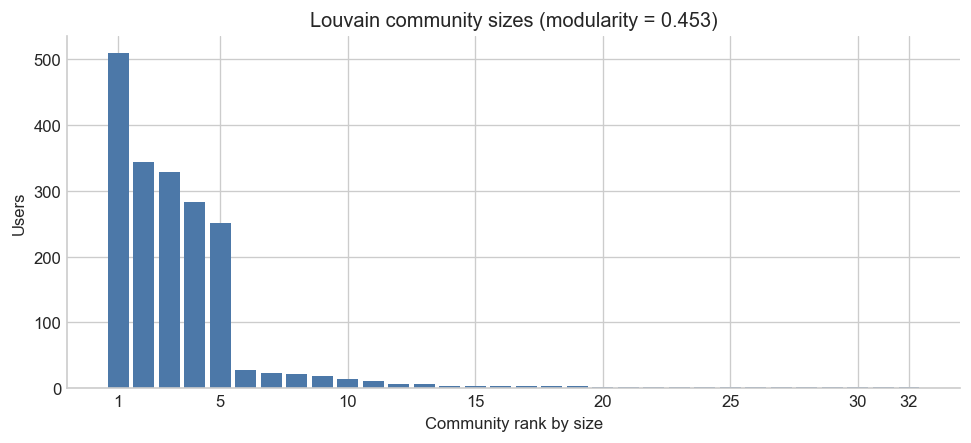

In [12]:
split = split_interactions(data.interactions)
sparse_labels = compute_sparse_labels(split)
community = detect_communities(data.interactions["user_id"], data.friendships)

assert sum(item["rows"] for item in split.summary.values()) == len(data.interactions)
assert len(sparse_labels.labels) == 1_876
assert sparse_labels.cutoff == 35
assert sparse_labels.labels["sparse"].astype(bool).all()
assert community.community_count == 32

split_summary = pd.DataFrame(split.summary).T.rename_axis("partition").reset_index()
display(split_summary)
print(f"Frozen sparse cutoff: {sparse_labels.cutoff}; sparse users: {int(sparse_labels.labels['sparse'].sum()):,}/{len(sparse_labels.labels):,}")
print(f"Louvain communities: {community.community_count}; modularity: {community.modularity:.4f}")

sizes = np.asarray(community.size_distribution)
fig, ax = plt.subplots(figsize=(8.2, 3.8))
ax.bar(np.arange(1, len(sizes) + 1), sizes, color="#4C78A8", width=0.82)
ax.set(title=f"Louvain community sizes (modularity = {community.modularity:.3f})",
       xlabel="Community rank by size", ylabel="Users")
ax.set_xticks([1, 5, 10, 15, 20, 25, 30, 32])
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 4. Recommendation methods

All methods rank the same phase-specific candidate set: fit-universe artists not already seen by the user. Global popularity sums `log1p(weight)`. Community popularity applies frozen shrinkage to a global activity distribution. Implicit ALS uses confidence `1 + alpha × log1p(weight)`, 20 iterations, one numerical thread, and deterministic raw-ID mappings. The hybrid combines per-user population-z-normalized ALS and log community scores only where both are finite. Binary relevance NDCG@10 is primary; Recall@10 and catalog coverage@10 are secondary.

## 5. Validation and model selection

Validation fitting uses only split-training plus low-history fit-only rows. The exact grid is eight ALS configurations, three community pseudo-masses, and nine hybrid `(beta, lambda)` combinations. Selection uses macro validation NDCG@10 and the frozen tie rules. The test ledger is deliberately not constructed until the selected settings are asserted against the frozen P4 configuration.

In [13]:
validation_ledger = build_phase_ledger(split, sparse_labels, phase="validation")
validation_started = perf_counter()
selection = run_validation_selection(validation_ledger, community.membership)
validation_runtime = perf_counter() - validation_started

expected_als = {
    "factors": 32, "regularization": 0.10, "alpha": 1.0,
    "iterations": 20, "seed": 5101,
}
expected_community = {"beta": 1000.0}
expected_hybrid = {"beta": 100.0, "lambda": 0.25}
assert dict(selection.best_als.parameters) == expected_als
assert dict(selection.best_community.parameters) == expected_community
assert dict(selection.best_hybrid.parameters) == expected_hybrid
assert len(selection.records) == 20
assert validation_ledger.summary["metric_eligible_users"] == 1_873

validation_table = pd.DataFrame([
    {
        "stage": record.stage,
        "parameters": ", ".join(f"{key}={value:g}" for key, value in record.parameters.items()
                                if key not in {"iterations", "seed"}),
        "NDCG@10": record.ndcg_at_10,
        "Recall@10": record.recall_at_10,
        "users": record.eligible_users,
        "failed": len(record.failed_users),
    }
    for record in selection.records
])
print(f"Validation completed in {validation_runtime:.1f} s; frozen selections reproduced.")
validation_table.round({"NDCG@10": 6, "Recall@10": 6})

Validation completed in 251.2 s; frozen selections reproduced.


,stage,parameters,NDCG@10,Recall@10,users,failed
0,als,"factors=32, regularization=0.01, alpha=1",0.197470,0.195168,1873,0
1,als,"factors=32, regularization=0.01, alpha=10",0.161377,0.169644,1873,0
2,als,"factors=32, regularization=0.1, alpha=1",0.197665,0.195375,1873,0
3,als,"factors=32, regularization=0.1, alpha=10",0.162180,0.171661,1873,0
4,als,"factors=64, regularization=0.01, alpha=1",0.188203,0.186525,1873,0
5,als,"factors=64, regularization=0.01, alpha=10",0.157379,0.164155,1873,0
6,als,"factors=64, regularization=0.1, alpha=1",0.188688,0.186892,1873,0
7,als,"factors=64, regularization=0.1, alpha=10",0.159110,0.166403,1873,0
8,community,beta=10,0.116799,0.111176,1873,0
9,community,beta=100,0.116717,0.111109,1873,0


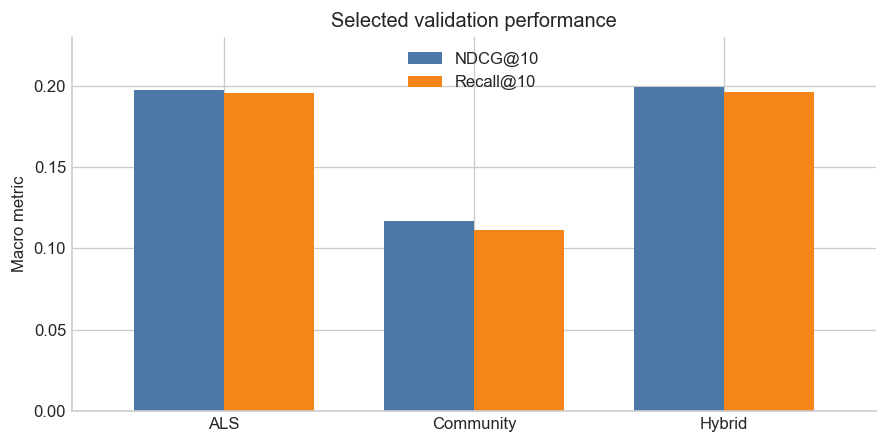

In [14]:
best_validation = pd.DataFrame([
    {"method": "ALS", "NDCG@10": selection.best_als.ndcg_at_10,
     "Recall@10": selection.best_als.recall_at_10},
    {"method": "Community", "NDCG@10": selection.best_community.ndcg_at_10,
     "Recall@10": selection.best_community.recall_at_10},
    {"method": "Hybrid", "NDCG@10": selection.best_hybrid.ndcg_at_10,
     "Recall@10": selection.best_hybrid.recall_at_10},
])
ax = best_validation.set_index("method").plot.bar(
    figsize=(7.5, 3.8), color=["#4C78A8", "#F58518"], width=0.72
)
ax.set(title="Selected validation performance", xlabel="", ylabel="Macro metric")
ax.set_ylim(0, 0.23)
ax.tick_params(axis="x", rotation=0)
ax.spines[["top", "right"]].set_visible(False)
ax.figure.tight_layout()
plt.show()

## 6. Final test evaluation

Only after validation choices match the frozen P4 configuration do we construct the test ledger. Selected methods are refit on training + validation + low-history fit-only rows. There is no post-test tuning. H2 is the paired user-level Hybrid-minus-ALS NDCG@10 difference with 2,000 bootstrap resamples (seed 5101); its criterion requires a positive estimate and a 95% percentile interval wholly above zero.

,method,ndcg_at_10,recall_at_10,coverage_at_10,metric_eligible_users,heldout_cold_pairs,failed_users
0,global_popularity,0.078076,0.081569,0.001806,1872,1635,0
1,als,0.239324,0.233646,0.050072,1872,1635,0
2,community,0.131956,0.125809,0.020863,1872,1635,0
3,hybrid,0.241904,0.233544,0.047767,1872,1635,0


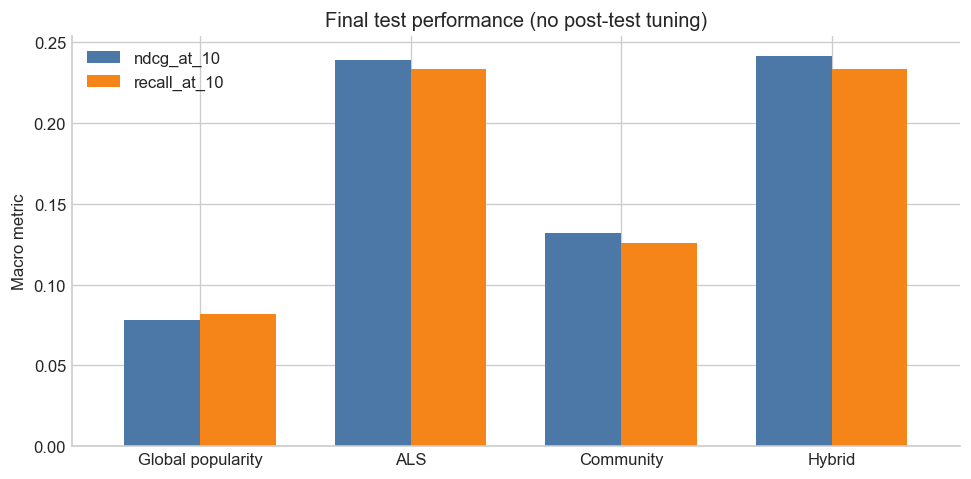

In [15]:
final_started = perf_counter()
test_ledger = build_phase_ledger(split, sparse_labels, phase="test")
validate_complete_sparse_labels(test_ledger, sparse_labels)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    final_als_model = fit_implicit_als(test_ledger.fitting_interactions, FROZEN_ALS)
final_warnings = tuple(str(item.message) for item in caught)
global_profile = fit_global_popularity(test_ledger.fitting_interactions)
community_profile = fit_community_popularity(
    test_ledger.fitting_interactions, community.membership, beta=FROZEN_COMMUNITY_BETA
)
hybrid_profile = fit_community_popularity(
    test_ledger.fitting_interactions, community.membership, beta=FROZEN_HYBRID_BETA
)
primary = _evaluate_models(
    test_ledger, "primary_fit_artist_universe", global_profile, final_als_model,
    community_profile, hybrid_profile, community.membership,
)
comparison = pd.DataFrame([
    _result_row(primary[name], test_ledger)
    for name in ("global_popularity", "als", "community", "hybrid")
])
display(comparison[["method", "ndcg_at_10", "recall_at_10", "coverage_at_10",
                    "metric_eligible_users", "heldout_cold_pairs", "failed_users"]]
        .round({"ndcg_at_10": 8, "recall_at_10": 8, "coverage_at_10": 8}))

metric_plot = comparison.set_index("method")[["ndcg_at_10", "recall_at_10"]]
metric_plot.index = ["Global popularity", "ALS", "Community", "Hybrid"]
ax = metric_plot.plot.bar(figsize=(8.2, 4.1), color=["#4C78A8", "#F58518"], width=0.72)
ax.set(title="Final test performance (no post-test tuning)", xlabel="", ylabel="Macro metric")
ax.tick_params(axis="x", rotation=0)
ax.spines[["top", "right"]].set_visible(False)
ax.figure.tight_layout()
plt.show()

H2 Hybrid − ALS NDCG@10 = 0.00257945; 95% paired bootstrap CI [-0.00000753, 0.00502635]
H2 criterion NOT met: False


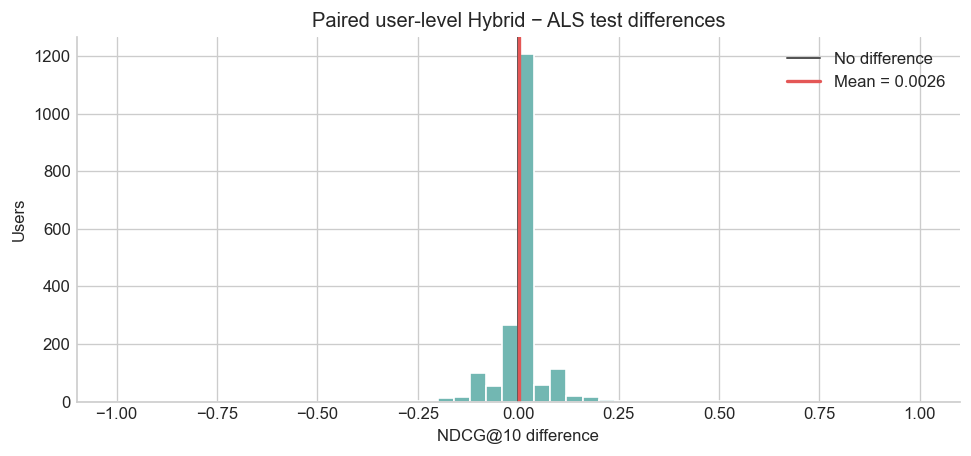

In [16]:
h2 = paired_ndcg_bootstrap(primary["als"].per_user, primary["hybrid"].per_user)
h2_differences = (
    primary["hybrid"].per_user["ndcg_at_10"].to_numpy()
    - primary["als"].per_user["ndcg_at_10"].to_numpy()
)
h2_met = h2.estimate > 0 and h2.ci_lower > 0
print(f"H2 Hybrid − ALS NDCG@10 = {h2.estimate:.8f}; "
      f"95% paired bootstrap CI [{h2.ci_lower:.8f}, {h2.ci_upper:.8f}]")
print("H2 criterion met:" if h2_met else "H2 criterion NOT met:", h2_met)

fig, ax = plt.subplots(figsize=(8.2, 3.9))
ax.hist(h2_differences, bins=np.linspace(-1, 1, 51), color="#72B7B2", edgecolor="white")
ax.axvline(0, color="#555555", linewidth=1.2, label="No difference")
ax.axvline(h2.estimate, color="#E45756", linewidth=2,
           label=f"Mean = {h2.estimate:.4f}")
ax.set(title="Paired user-level Hybrid − ALS test differences",
       xlabel="NDCG@10 difference", ylabel="Users")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 7. Robustness and limitations

Supporting analyses are not substitutes for H2. H1 is descriptive and approximate because users and selected peers overlap. H3 is reported non-estimable if the frozen labels lack both sparse and non-sparse groups; the definition is not changed. A seeded shuffled-community control tests whether labels carry useful structure. A full-catalog sensitivity expands candidates to all audited artists and explicitly treats fit-absent representations as missing sentinels; it is not evidence of learned item cold start.

H1 anchors: 1,869; within − cross Jaccard = 0.02017763
Descriptive jackknife SE = 0.00206150; 95% normal interval [0.01613708, 0.02421818]
Candidate anchors by stratum: {'5-10': 10, '11-20': 5, '21-50': 1854, '51+': 0}; maximum peer reuse: 9


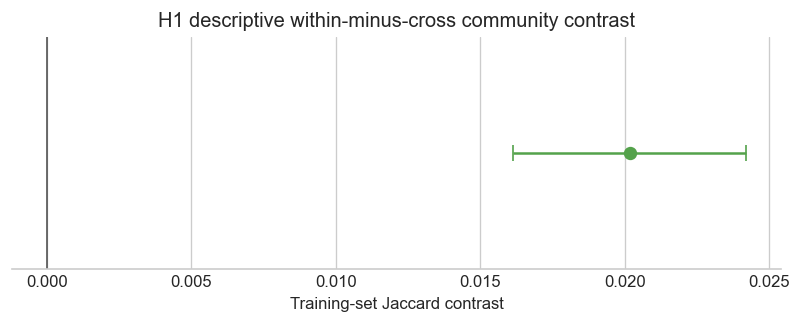

In [17]:
h1 = run_h1_analysis(split.table, community.membership)
print(f"H1 anchors: {len(h1.anchors):,}; within − cross Jaccard = {h1.mean_contrast:.8f}")
print(f"Descriptive jackknife SE = {h1.jackknife_se:.8f}; "
      f"95% normal interval [{h1.ci_lower:.8f}, {h1.ci_upper:.8f}]")
print(f"Candidate anchors by stratum: {dict(h1.candidate_anchor_counts)}; "
      f"maximum peer reuse: {int(h1.peer_reuse.use_count.max())}")

fig, ax = plt.subplots(figsize=(6.8, 2.8))
ax.errorbar([h1.mean_contrast], [0],
            xerr=[[h1.mean_contrast - h1.ci_lower], [h1.ci_upper - h1.mean_contrast]],
            fmt="o", markersize=7, color="#54A24B", capsize=5)
ax.axvline(0, color="#555555", linewidth=1)
ax.set(title="H1 descriptive within-minus-cross community contrast",
       xlabel="Training-set Jaccard contrast", yticks=[])
ax.spines[["top", "right", "left"]].set_visible(False)
fig.tight_layout()
plt.show()

,method,candidate_policy,ndcg_at_10,recall_at_10,metric_eligible_users,cold_catalog_candidates,missing_representation_candidates,valid_zero_probability_candidates,missing_component_candidates,failed_users
0,shuffled_community,primary_fit_artist_universe,0.075667,0.078730,1872,0,0,0,0,0
1,shuffled_hybrid,primary_fit_artist_universe,0.235019,0.227515,1872,0,0,0,0,0
2,global_popularity,full_catalog_sensitivity,0.074904,0.076292,1876,2954700,0,0,0,0
3,als,full_catalog_sensitivity,0.226267,0.213133,1876,2954700,2954700,0,0,0
4,community,full_catalog_sensitivity,0.126024,0.116654,1876,2954700,0,2954700,0,0
5,hybrid,full_catalog_sensitivity,0.228934,0.213324,1876,2954700,0,0,2954700,0


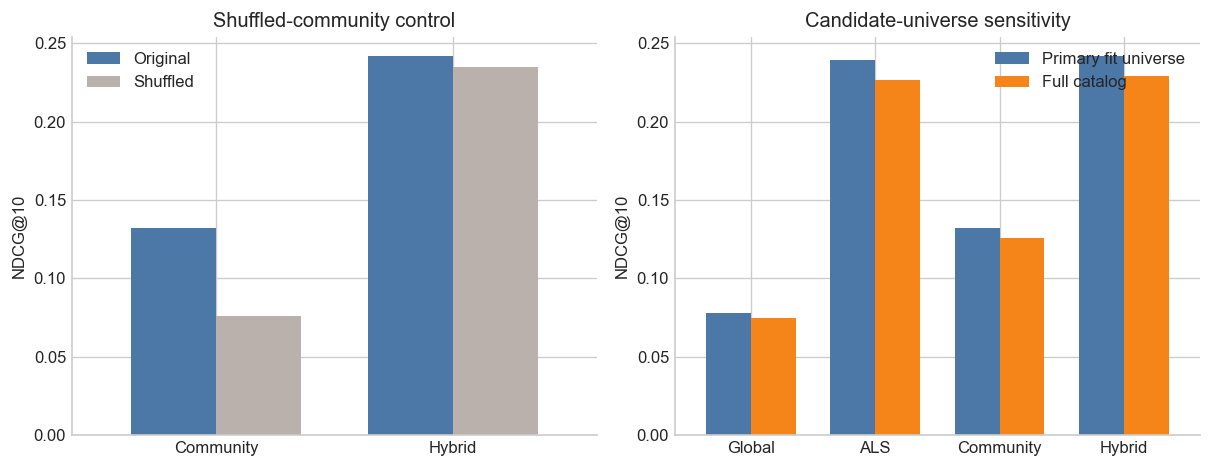

In [18]:
shuffled = shuffle_community_assignments(community.membership)
shuffled_community_profile = fit_community_popularity(
    test_ledger.fitting_interactions, shuffled, beta=FROZEN_COMMUNITY_BETA
)
shuffled_hybrid_profile = fit_community_popularity(
    test_ledger.fitting_interactions, shuffled, beta=FROZEN_HYBRID_BETA
)
shuffled_results = {
    "shuffled_community": evaluate_method(
        "shuffled_community", "primary_fit_artist_universe", test_ledger,
        lambda user, candidates: community_candidate_scores(
            shuffled_community_profile, shuffled, user, candidates
        ),
    ),
    "shuffled_hybrid": evaluate_method(
        "shuffled_hybrid", "primary_fit_artist_universe", test_ledger,
        lambda user, candidates: hybrid_candidate_scores(
            als_candidate_scores(final_als_model, user, candidates),
            community_candidate_scores(shuffled_hybrid_profile, shuffled, user, candidates),
            lambda_=FROZEN_HYBRID_LAMBDA,
        ),
    ),
}
for result in shuffled_results.values():
    assert not result.failed_user_ids
    assert result.eligible_user_ids == primary["als"].eligible_user_ids

catalog_ledger = full_catalog_ledger(test_ledger, data.artists["artist_id"].astype(int).tolist())
sensitivity = _evaluate_models(
    catalog_ledger, "full_catalog_sensitivity", global_profile, final_als_model,
    community_profile, hybrid_profile, community.membership,
)
robustness = pd.DataFrame([
    _result_row(shuffled_results["shuffled_community"], test_ledger),
    _result_row(shuffled_results["shuffled_hybrid"], test_ledger),
    *[_result_row(sensitivity[name], catalog_ledger)
      for name in ("global_popularity", "als", "community", "hybrid")],
])
display(robustness[["method", "candidate_policy", "ndcg_at_10", "recall_at_10",
                    "metric_eligible_users", "cold_catalog_candidates",
                    "missing_representation_candidates", "valid_zero_probability_candidates",
                    "missing_component_candidates", "failed_users"]]
        .round({"ndcg_at_10": 8, "recall_at_10": 8}))

fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.0))
original_control = pd.DataFrame({
    "Original": [primary["community"].ndcg_at_10, primary["hybrid"].ndcg_at_10],
    "Shuffled": [shuffled_results["shuffled_community"].ndcg_at_10,
                 shuffled_results["shuffled_hybrid"].ndcg_at_10],
}, index=["Community", "Hybrid"])
original_control.plot.bar(ax=axes[0], color=["#4C78A8", "#BAB0AC"], width=0.72)
axes[0].set(title="Shuffled-community control", xlabel="", ylabel="NDCG@10")
axes[0].tick_params(axis="x", rotation=0)

primary_full = pd.DataFrame({
    "Primary fit universe": [primary[name].ndcg_at_10 for name in
                             ("global_popularity", "als", "community", "hybrid")],
    "Full catalog": [sensitivity[name].ndcg_at_10 for name in
                     ("global_popularity", "als", "community", "hybrid")],
}, index=["Global", "ALS", "Community", "Hybrid"])
primary_full.plot.bar(ax=axes[1], color=["#4C78A8", "#F58518"], width=0.72)
axes[1].set(title="Candidate-universe sensitivity", xlabel="", ylabel="NDCG@10")
axes[1].tick_params(axis="x", rotation=0)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

In [19]:
# Independent P5 checkpoint gates. Any discrepancy stops execution.
expected_primary = {
    "als": 0.2393242136,
    "hybrid": 0.2419036648,
    "community": 0.1319556633,
    "global_popularity": 0.0780761828,
}
expected_full = {
    "global_popularity": 0.0749037817,
    "als": 0.2262669118,
    "community": 0.1260242187,
    "hybrid": 0.2289340618,
}
assert test_ledger.summary["metric_eligible_users"] == 1_872
assert test_ledger.summary["primary_artist_universe_size"] == 16_057
assert test_ledger.summary["cold_heldout_pairs"] == 1_635
for name, expected in expected_primary.items():
    assert np.isclose(primary[name].ndcg_at_10, expected, rtol=0, atol=CHECKPOINT_ATOL), name
for name, expected in expected_full.items():
    assert np.isclose(sensitivity[name].ndcg_at_10, expected, rtol=0, atol=CHECKPOINT_ATOL), name
assert np.isclose(h2.estimate, 0.0025794511, rtol=0, atol=CHECKPOINT_ATOL)
assert h2.ci_lower <= 0 <= h2.ci_upper
assert not h2_met
assert np.isclose(h1.mean_contrast, 0.0201776287, rtol=0, atol=CHECKPOINT_ATOL)
assert len(h1.anchors) == 1_869
assert np.isclose(shuffled_results["shuffled_community"].ndcg_at_10,
                  0.0756674664, rtol=0, atol=CHECKPOINT_ATOL)
assert np.isclose(shuffled_results["shuffled_hybrid"].ndcg_at_10,
                  0.2350188885, rtol=0, atol=CHECKPOINT_ATOL)
assert catalog_ledger.summary["metric_eligible_users"] == 1_876
assert len(catalog_ledger.primary_artist_universe) == 17_632
assert not selection.h3_estimable
assert sparse_labels.labels["sparse"].astype(bool).all()
h3 = {
    "estimable": False,
    "reason": "all 1,876 eligible users are sparse under the frozen split-training label",
    "sparse_cutoff": sparse_labels.cutoff,
    "sparse_users": int(sparse_labels.labels["sparse"].sum()),
    "non_sparse_users": int((~sparse_labels.labels["sparse"].astype(bool)).sum()),
}
final_runtime = perf_counter() - final_started
analysis_runtime = perf_counter() - analysis_started
print(f"All frozen checkpoints passed at absolute tolerance {CHECKPOINT_ATOL:g}.")
print("H3 is non-estimable; the frozen sparse definition was not changed.")

All frozen checkpoints passed at absolute tolerance 1e-06.
H3 is non-estimable; the frozen sparse definition was not changed.


The H2 point estimate is positive, but its confidence interval spans zero, so the predeclared criterion is **not met**. H1 shows a positive descriptive within-community contrast, but it is neither causal nor a population-level significance result. H3 is **non-estimable** because every raw-eligible user is sparse under the frozen split-training cutoff; no alternative definition is introduced. Results remain conditional on this small, historical convenience sample, aggregate counts, a static friendship graph, random-within-user holdout, and retrievable relevance under the candidate policy.

## 8. Reproducibility

This notebook reads only the original ZIP and reconstructs every split, label, ledger, profile, model, selection, and result in memory. It does not read project source modules, agent-task records, Git state, or precomputed CSV/Parquet outputs. Exact runtime dependencies are declared in the submitted `requirements.txt`; execution is verified on Python 3.11 with one numerical thread. Low-order ALS differences can vary across hardware/BLAS builds, so the independent numerical checkpoints use absolute tolerance `1e-6`; all identifiers, counts, grids, selections, and estimability decisions are exact.

In [20]:
package_names = ["implicit", "ipykernel", "matplotlib", "nbclient", "nbformat",
                 "networkx", "numpy", "pandas", "scipy"]
reproducibility = pd.DataFrame({
    "item": ["protocol", "archive SHA-256", "Python", "platform",
             "validation runtime (s)", "final/robustness runtime (s)",
             "total analysis runtime (s)", "checkpoint absolute tolerance",
             *package_names],
    "value": [PROTOCOL_ID, ARCHIVE_SHA256, platform.python_version(), platform.platform(),
              f"{validation_runtime:.3f}", f"{final_runtime:.3f}", f"{analysis_runtime:.3f}",
              f"{CHECKPOINT_ATOL:g}",
              *[importlib.metadata.version(name) for name in package_names]],
})
display(reproducibility)
print("Execution complete: all cells ran in order from a fresh Python 3.11 kernel.")

,item,value
0,protocol,lastfm-v1
1,archive SHA-256,6738f48195667ff03caaab4d32ca9a3133d8cc026b7c3c...
2,Python,3.11.0
3,platform,macOS-26.6.2-arm64-arm-64bit
4,validation runtime (s),251.216
5,final/robustness runtime (s),234.575
6,total analysis runtime (s),490.792
7,checkpoint absolute tolerance,1e-06
8,implicit,0.7.2
9,ipykernel,7.1.0


Execution complete: all cells ran in order from a fresh Python 3.11 kernel.
